# Financial Market Risk Profiling and Regime Detection
### Clustering · Gaussian Mixture Models · Hidden Markov Models · Linear Dynamical Systems
**Machine Learning: Project Review 2**
**Made by:** Srushti More [298], Agadh Khanolkar [299], Sneh Prasad [311]

This single notebook contains **all** of the project's code and runs it end to end:

| Part | Question | Methods |
|---|---|---|
| **A: Unit III** | Which stocks share a risk profile? | 7 risk features → PCA → K-means, GMM, Hierarchical; Manhattan / Cosine / Mahalanobis; silhouette, DB, CH; ARI stability |
| **B: Unit IV** | Which market regime are we in? | 3-state Gaussian HMM; our own NumPy **Sum-Product** and **Viterbi**; Kalman-filter **LDS** comparison |

**How to run:** *Kernel → Restart & Run All* (about 1 minute). Data is read from `data/raw/` if it is present; otherwise it is downloaded (yfinance → NSE eod2 dataset on GitHub). Simulated data is used only as a last resort, and is then clearly labelled **SYNTHETIC**.

## 0. Setup
The next cell installs any missing packages (safe to re-run).

In [37]:
%pip install numpy pandas scipy scikit-learn matplotlib seaborn hmmlearn yfinance

Note: you may need to restart the kernel to use updated packages.


In [38]:
import io, json, logging, time, warnings, itertools, urllib.parse, urllib.request
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.special import logsumexp
from scipy.optimize import minimize
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.covariance import LedoitWolf
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score)
from hmmlearn.hmm import GaussianHMM

%matplotlib inline
warnings.filterwarnings("ignore")
logging.getLogger("yfinance").setLevel(logging.CRITICAL)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20); pd.set_option("display.precision", 4)


def banner(txt):
    print("\n" + "=" * 78 + f"\n  {txt}\n" + "=" * 78)


def jsonable(o):
    if isinstance(o, dict):
        return {str(k): jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [jsonable(v) for v in o]
    if isinstance(o, np.ndarray):
        return jsonable(o.tolist())
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.integer):
        return int(o)
    return o

### Configuration (tickers, windows, seeds, K, restarts)

In [39]:
from pathlib import Path


class config:
    """All settings in one place (same values as config.py)."""
    # ---------------------------------------------------------------- paths
    ROOT = Path.cwd()   # run the notebook from the project folder (or any folder)
    DATA_DIR = ROOT / "data"
    RAW_DIR = DATA_DIR / "raw"
    OUT_DIR = ROOT / "outputs"
    FIG_DIR = OUT_DIR / "figures"
    TAB_DIR = OUT_DIR / "tables"
    RES_DIR = OUT_DIR / "results"

    # ---------------------------------------------------------------- reproducibility
    SEED = 42

    # ---------------------------------------------------------------- Part A: asset universe
    # 12 NSE (India) large caps across 9 sectors.
    # key = short name used everywhere; value = (yfinance ticker, eod2 file name, sector)
    STOCKS = {
        "RELIANCE":   ("RELIANCE.NS",   "reliance",   "Energy"),
        "TCS":        ("TCS.NS",        "tcs",        "IT Services"),
        "INFY":       ("INFY.NS",       "infy",       "IT Services"),
        "HDFCBANK":   ("HDFCBANK.NS",   "hdfcbank",   "Banking"),
        "ICICIBANK":  ("ICICIBANK.NS",  "icicibank",  "Banking"),
        "HINDUNILVR": ("HINDUNILVR.NS", "hindunilvr", "FMCG"),
        "ITC":        ("ITC.NS",        "itc",        "FMCG"),
        "SUNPHARMA":  ("SUNPHARMA.NS",  "sunpharma",  "Pharma"),
        "MARUTI":     ("MARUTI.NS",     "maruti",     "Automobile"),
        "TATASTEEL":  ("TATASTEEL.NS",  "tatasteel",  "Metals"),
        "BHARTIARTL": ("BHARTIARTL.NS", "bhartiartl", "Telecom"),
        "LT":         ("LT.NS",         "lt",         "Infrastructure"),
    }
    STOCK_START = "2021-10-01"   # ~5 years of daily data
    STOCK_END = "2026-09-25"     # last date available in the cached dataset

    # ---------------------------------------------------------------- Part B: market index
    INDEX_NAME = "NIFTY50"
    INDEX_YF = "^NSEI"
    INDEX_EOD2 = "nifty 50"
    INDEX_START = "2015-01-01"   # longer window so the HMM sees several regimes (incl. 2020 crash)
    INDEX_END = STOCK_END
    TRAIN_END = "2023-12-31"     # chronological split: train <= TRAIN_END < test

    # ---------------------------------------------------------------- data sources
    # Tried in this order unless a cache exists (see data_loader.load_* functions).
    EOD2_URL = "https://raw.githubusercontent.com/BennyThadikaran/eod2_data/main/daily/{name}.csv"

    # ---------------------------------------------------------------- Part A settings
    RETURN_TYPE = "log"           # daily log returns
    VAR_LEVEL = 0.95              # VaR / CVaR confidence
    K_RANGE = range(2, 7)         # candidate cluster counts (n_assets = 12)
    N_CLUSTERS = None             # None -> chosen automatically by silhouette (K-means)
    LINKAGES = ["ward", "average", "complete"]
    PCA_VARIANCE_TARGET = 0.80    # keep the fewest PCs explaining >= 80% variance
    N_SEED_RUNS = 50              # initialisation-stability runs
    N_BOOTSTRAP = 100             # block-bootstrap stability runs
    BOOTSTRAP_BLOCK = 20          # trading days per block (~1 month) keeps volatility clustering
    MAHALANOBIS_SHRINKAGE = "ledoit_wolf"

    # ---------------------------------------------------------------- Part B settings
    HMM_STATES = 3
    HMM_RESTARTS = 10             # random restarts of Baum-Welch, best train log-lik kept
    HMM_N_ITER = 500
    ROLLING_VOL_WINDOW = 21       # ~1 trading month
    RETURN_SCALE = 100.0          # model returns in percent for numerical conditioning


for _d in (config.FIG_DIR, config.TAB_DIR, config.RES_DIR, config.RAW_DIR):
    _d.mkdir(parents=True, exist_ok=True)
print('Working folder:', config.ROOT)


Working folder: d:\ML Review 2\financial-risk-regime-project


In [40]:
class args:                 # run options (same as the command-line flags of main.py)
    source = None           # None = automatic fallback; or "cache" | "yfinance" | "eod2" | "synthetic"
    refresh_data = False    # True = ignore the local cache and download again
    quick = False           # True = fewer bootstrap / restart iterations (faster demo)

np.random.seed(config.SEED)
results = {"config": {"seed": config.SEED, "quick": args.quick, "source_flag": args.source}}
T_START = time.time()

## 1. Data acquisition and preprocessing
Ordered fallback: **cache → yfinance → eod2 (NSE, GitHub) → synthetic**. We align trading dates, forward-fill gaps of 3 days or less, **never back-fill** (that would leak future prices), and use daily log returns.

In [41]:
import io
import json
import urllib.parse
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd


SOURCES = ("cache", "yfinance", "eod2", "synthetic")


# ------------------------------------------------------------------ helpers
def _meta_path(kind: str) -> Path:
    return config.RAW_DIR / f"{kind}_source.json"


def _save_cache(df: pd.DataFrame, kind: str, source: str) -> None:
    config.RAW_DIR.mkdir(parents=True, exist_ok=True)
    df.to_csv(config.RAW_DIR / f"{kind}_prices.csv", index_label="Date")
    _meta_path(kind).write_text(json.dumps({"source": source}, indent=2))


def _load_cache(kind: str) -> tuple[pd.DataFrame, str] | None:
    path = config.RAW_DIR / f"{kind}_prices.csv"
    if not path.exists():
        return None
    df = pd.read_csv(path, index_col="Date", parse_dates=True)
    src = "unknown"
    if _meta_path(kind).exists():
        src = json.loads(_meta_path(kind).read_text()).get("source", "unknown")
    return df, f"cache ({src})"


def _clean(df: pd.DataFrame, start: str, end: str) -> pd.DataFrame:
    """Align trading dates and handle missing values.

    * keep only the requested window
    * drop dates where *every* series is missing (exchange holidays)
    * forward-fill gaps of at most 3 days (isolated missing prints), never back-fill
      (back-filling would leak future prices into the past)
    * drop any remaining rows with NaN so all assets share one calendar
    """
    df = df.sort_index()
    df = df.loc[(df.index >= pd.Timestamp(start)) & (df.index <= pd.Timestamp(end))]
    df = df.dropna(how="all")
    df = df.ffill(limit=3).dropna(how="any")
    df = df[(df > 0).all(axis=1)]
    return df


def _from_yfinance(tickers: dict[str, str], start: str, end: str) -> pd.DataFrame:
    import yfinance as yf  # optional dependency

    end_excl = (pd.Timestamp(end) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
    raw = yf.download(list(tickers.values()), start=start, end=end_excl,
                      auto_adjust=True, progress=False, threads=True)
    if raw is None or raw.empty:
        raise RuntimeError("yfinance returned no data")
    close = raw["Close"] if isinstance(raw.columns, pd.MultiIndex) else raw[["Close"]]
    if isinstance(close, pd.Series):
        close = close.to_frame()
    inv = {v: k for k, v in tickers.items()}
    close = close.rename(columns=inv)
    if len(tickers) == 1 and list(close.columns) == ["Close"]:
        close.columns = list(tickers.keys())
    missing = set(tickers) - set(close.columns)
    if missing or close.dropna(how="all").shape[0] < 100:
        raise RuntimeError(f"yfinance incomplete (missing={missing})")
    close.index = pd.to_datetime(close.index).tz_localize(None)
    return close


def _from_eod2(names: dict[str, str], start: str, end: str) -> pd.DataFrame:
    frames = {}
    for key, name in names.items():
        url = config.EOD2_URL.format(name=urllib.parse.quote(name))
        with urllib.request.urlopen(url, timeout=60) as resp:
            text = resp.read().decode("utf-8")
        df = pd.read_csv(io.StringIO(text), parse_dates=["Date"], index_col="Date")
        frames[key] = df["Close"].astype(float)
    return pd.DataFrame(frames)


def synthetic_prices(names: list[str], start: str, end: str, seed: int = config.SEED,
                     regime_switching: bool = False) -> pd.DataFrame:
    """SYNTHETIC prices (clearly not market data).

    Assets are generated from a 2-factor model with per-asset betas, volatilities and
    Student-t shocks so the risk features differ meaningfully between assets.
    With ``regime_switching`` a 3-state Markov chain drives drift/volatility (used for
    the synthetic index so the HMM has real structure to recover).
    """
    rng = np.random.default_rng(seed)
    dates = pd.bdate_range(start, end)
    T, N = len(dates), len(names)
    if regime_switching:
        mu = np.array([0.06, -0.08, -0.05])  # % per day: bull, bear, high-vol
        sd = np.array([0.7, 1.1, 2.6])
        P = np.array([[0.985, 0.010, 0.005], [0.020, 0.970, 0.010], [0.030, 0.020, 0.950]])
        s = np.zeros(T, dtype=int)
        for t in range(1, T):
            s[t] = rng.choice(3, p=P[s[t - 1]])
        r = (mu[s] + sd[s] * rng.standard_normal(T)) / 100
        prices = 10000 * np.exp(np.cumsum(r))
        return pd.DataFrame({names[0]: prices}, index=dates)
    market = rng.standard_t(5, T) * 0.009
    style = rng.standard_t(5, T) * 0.006
    beta = rng.uniform(0.5, 1.5, N)
    gamma = rng.uniform(-1, 1, N)
    idio = rng.uniform(0.006, 0.02, N)
    drift = rng.uniform(-0.0002, 0.0008, N)
    shocks = rng.standard_t(4, (T, N)) * idio / np.sqrt(2)
    r = drift + np.outer(market, beta) + np.outer(style, gamma) + shocks
    prices = 100 * np.exp(np.cumsum(r, axis=0))
    return pd.DataFrame(prices, index=dates, columns=names)


def _load(kind: str, yf_map: dict, eod_map: dict, start: str, end: str,
          prefer: str | None, refresh: bool, regime_switching: bool):
    order = list(SOURCES)
    if prefer:
        order = [prefer]
    elif refresh:
        order = [s for s in SOURCES if s != "cache"]
    errors = {}
    for src in order:
        try:
            if src == "cache":
                hit = _load_cache(kind)
                if hit is None:
                    raise FileNotFoundError("no cache")
                df, label = hit
                return _clean(df, start, end), label
            if src == "yfinance":
                df = _from_yfinance(yf_map, start, end)
            elif src == "eod2":
                df = _from_eod2(eod_map, start, end)
            else:
                df = synthetic_prices(list(yf_map), start, end,
                                      regime_switching=regime_switching)
            df = _clean(df, start, end)
            if src != "synthetic":
                _save_cache(df, kind, src)
            label = "SYNTHETIC (simulated, not market data)" if src == "synthetic" else src
            return df, label
        except Exception as exc:  # noqa: BLE001 -- we report and fall through
            errors[src] = f"{type(exc).__name__}: {str(exc)[:120]}"
    raise RuntimeError(f"All data sources failed: {errors}")


def load_stock_prices(prefer: str | None = None, refresh: bool = False):
    yf_map = {k: v[0] for k, v in config.STOCKS.items()}
    eod_map = {k: v[1] for k, v in config.STOCKS.items()}
    return _load("stocks", yf_map, eod_map, config.STOCK_START, config.STOCK_END,
                 prefer, refresh, regime_switching=False)


def load_index_prices(prefer: str | None = None, refresh: bool = False):
    yf_map = {config.INDEX_NAME: config.INDEX_YF}
    eod_map = {config.INDEX_NAME: config.INDEX_EOD2}
    df, label = _load("index", yf_map, eod_map, config.INDEX_START, config.INDEX_END,
                      prefer, refresh, regime_switching=True)
    return df[config.INDEX_NAME], label


def log_returns(prices: pd.DataFrame | pd.Series):
    """Daily log returns r_t = ln(P_t / P_{t-1}); first row dropped."""
    return np.log(prices / prices.shift(1)).dropna()


## 2. Risk features
Mean, volatility, skewness, excess kurtosis, historical **VaR95**, **CVaR95** and **max drawdown**, all on daily log returns, then z-scored.

In [42]:
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.preprocessing import StandardScaler

FEATURES = ["mean_return", "volatility", "skewness", "kurtosis", "VaR_95", "CVaR_95",
            "max_drawdown"]

TRADING_DAYS = 252


def max_drawdown(returns: pd.Series) -> float:
    """Largest peak-to-trough fall of the cumulative wealth curve, as a positive fraction."""
    wealth = np.exp(np.cumsum(np.asarray(returns, dtype=float)))
    wealth = np.concatenate([[1.0], wealth])
    peak = np.maximum.accumulate(wealth)
    return float(np.max(1.0 - wealth / peak))


def historical_var_cvar(returns, level: float = 0.95) -> tuple[float, float]:
    """Historical VaR and CVaR (expected shortfall) reported as positive daily losses.

    VaR_a  = -quantile_{1-a}(r)
    CVaR_a = -E[r | r <= quantile_{1-a}(r)]
    """
    r = np.asarray(returns, dtype=float)
    q = np.quantile(r, 1 - level)
    tail = r[r <= q]
    return float(-q), float(-tail.mean())


def compute_risk_features(returns: pd.DataFrame, level: float = 0.95) -> pd.DataFrame:
    """Return an (N assets x 7 features) DataFrame.

    mean_return and volatility are daily figures (not annualised) so every feature is on the
    daily horizon; kurtosis is *excess* kurtosis (normal = 0).
    """
    rows = {}
    for col in returns.columns:
        r = returns[col].dropna()
        var, cvar = historical_var_cvar(r, level)
        rows[col] = {
            "mean_return": r.mean(),
            "volatility": r.std(ddof=1),
            "skewness": stats.skew(r, bias=False),
            "kurtosis": stats.kurtosis(r, fisher=True, bias=False),
            "VaR_95": var,
            "CVaR_95": cvar,
            "max_drawdown": max_drawdown(r),
        }
    return pd.DataFrame(rows).T[FEATURES].astype(float)


def standardize(features: pd.DataFrame) -> tuple[np.ndarray, StandardScaler]:
    """z-score each feature: distance-based methods otherwise weight features by their units."""
    scaler = StandardScaler()
    return scaler.fit_transform(features.values), scaler


def annualised_view(features: pd.DataFrame) -> pd.DataFrame:
    """Human-readable version for the summary table (annualised return/vol, % units)."""
    out = pd.DataFrame(index=features.index)
    out["Ann. return %"] = features["mean_return"] * TRADING_DAYS * 100
    out["Ann. vol %"] = features["volatility"] * np.sqrt(TRADING_DAYS) * 100
    out["Skew"] = features["skewness"]
    out["Ex. kurtosis"] = features["kurtosis"]
    out["VaR95 %"] = features["VaR_95"] * 100
    out["CVaR95 %"] = features["CVaR_95"] * 100
    out["Max DD %"] = features["max_drawdown"] * 100
    return out


## 3. Dissimilarity metrics
Manhattan, Cosine (scale-invariant; near-zero vectors are flagged) and Mahalanobis (**Ledoit-Wolf shrinkage + pseudo-inverse**, because 12 assets and 7 correlated features make the covariance near-singular).

In [43]:
import numpy as np
from scipy.spatial.distance import pdist, squareform
from sklearn.covariance import LedoitWolf

EPS = 1e-12


def manhattan_matrix(X: np.ndarray) -> np.ndarray:
    return squareform(pdist(X, metric="cityblock"))


def euclidean_matrix(X: np.ndarray) -> np.ndarray:
    return squareform(pdist(X, metric="euclidean"))


def cosine_matrix(X: np.ndarray, near_zero_tol: float = 0.25) -> tuple[np.ndarray, list[int]]:
    """Cosine distance + indices of rows whose norm is suspiciously small.

    near_zero_tol is relative to the median row norm.
    """
    norms = np.linalg.norm(X, axis=1)
    flagged = list(np.where(norms < near_zero_tol * np.median(norms))[0])
    Xs = X / np.maximum(norms, EPS)[:, None]
    D = 1.0 - Xs @ Xs.T
    D = np.clip((D + D.T) / 2, 0.0, 2.0)
    np.fill_diagonal(D, 0.0)
    return D, flagged


def shrunk_precision(X: np.ndarray) -> tuple[np.ndarray, dict]:
    """Ledoit-Wolf shrunk covariance -> pseudo-inverse. Returns precision + diagnostics."""
    lw = LedoitWolf().fit(X)
    S = lw.covariance_
    raw = np.cov(X, rowvar=False)
    info = {
        "shrinkage": float(lw.shrinkage_),
        "cond_raw_cov": float(np.linalg.cond(raw)),
        "cond_shrunk_cov": float(np.linalg.cond(S)),
        "rank_raw_cov": int(np.linalg.matrix_rank(raw)),
    }
    return np.linalg.pinv(S, hermitian=True), info


def mahalanobis_matrix(X: np.ndarray) -> tuple[np.ndarray, dict]:
    VI, info = shrunk_precision(X)
    D = squareform(pdist(X, metric="mahalanobis", VI=VI))
    return D, info


def validate_distance_matrix(D: np.ndarray, tol: float = 1e-9) -> dict:
    """Checks every dissimilarity must satisfy before clustering on it."""
    return {
        "symmetric": bool(np.allclose(D, D.T, atol=tol)),
        "zero_diagonal": bool(np.allclose(np.diag(D), 0.0, atol=tol)),
        "non_negative": bool((D >= -tol).all()),
        "finite": bool(np.isfinite(D).all()),
    }


def all_distance_matrices(X: np.ndarray) -> dict:
    cos, flagged = cosine_matrix(X)
    mah, info = mahalanobis_matrix(X)
    return {
        "Euclidean": {"D": euclidean_matrix(X), "notes": {}},
        "Manhattan": {"D": manhattan_matrix(X), "notes": {}},
        "Cosine": {"D": cos, "notes": {"near_zero_rows": flagged}},
        "Mahalanobis": {"D": mah, "notes": info},
    }


## 4. Clustering algorithms
K-means (squared Euclidean only), GMM (EM, spherical/diag with a variance floor) and agglomerative clustering. **Ward is Euclidean only** and is refused for precomputed distances.

In [44]:
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import linkage
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score
from sklearn.mixture import GaussianMixture


GMM_REG_COVAR = 0.1


# ------------------------------------------------------------------ K-means
def kmeans_fit(X, k, seed=config.SEED, n_init=20):
    """Lloyd's algorithm with k-means++ init; minimises within-cluster *squared Euclidean*
    distance (it is not defined for Manhattan/Cosine/Mahalanobis)."""
    return KMeans(n_clusters=k, n_init=n_init, random_state=seed).fit(X)


def kmeans_sweep(X, k_range=config.K_RANGE, seed=config.SEED) -> pd.DataFrame:
    rows = []
    for k in k_range:
        if k >= len(X):
            continue
        km = kmeans_fit(X, k, seed)
        rows.append({"k": k, "inertia": km.inertia_,
                     "silhouette": silhouette_score(X, km.labels_)})
    return pd.DataFrame(rows)


# ------------------------------------------------------------------ GMM
def gmm_fit(X, k, covariance_type="spherical", seed=config.SEED, n_init=10):
    """EM-fitted Gaussian mixture. With n=12 assets and p=7 features a *full* covariance per
    component (28 params each) is not identifiable, so 'diag'/'spherical' are used and a
    variance floor (reg_covar=0.1 in standardised units) stops EM from shrinking a component
    onto 2-3 assets -- without it BIC keeps improving as k grows, which is overfitting."""
    return GaussianMixture(n_components=k, covariance_type=covariance_type,
                           n_init=n_init, random_state=seed, reg_covar=GMM_REG_COVAR).fit(X)


def gmm_sweep(X, k_range=range(1, 6), cov_types=("spherical", "diag"),
              seed=config.SEED) -> pd.DataFrame:
    rows = []
    for cov in cov_types:
        for k in k_range:
            if k >= len(X):
                continue
            g = gmm_fit(X, k, cov, seed)
            labels = g.predict(X)
            sil = silhouette_score(X, labels) if 1 < len(set(labels)) < len(X) else np.nan
            rows.append({"covariance": cov, "k": k, "bic": g.bic(X), "aic": g.aic(X),
                         "silhouette": sil, "n_used": len(set(labels))})
    return pd.DataFrame(rows)


# ------------------------------------------------------------------ hierarchical
def hierarchical_fit(X, k, linkage_method="ward"):
    """Ward is only valid with Euclidean geometry (it merges the pair that least increases
    the within-cluster sum of squares)."""
    return AgglomerativeClustering(n_clusters=k, linkage=linkage_method,
                                   metric="euclidean").fit(X)


def hierarchical_precomputed(D, k, linkage_method="average"):
    """Agglomerative clustering on an arbitrary precomputed dissimilarity.
    Only average/complete/single linkage are valid here -- never Ward."""
    if linkage_method == "ward":
        raise ValueError("Ward linkage requires Euclidean distances; not allowed with "
                         "precomputed dissimilarities.")
    return AgglomerativeClustering(n_clusters=k, linkage=linkage_method,
                                   metric="precomputed").fit(D)


def linkage_matrix(X, method="ward"):
    return linkage(X, method=method, metric="euclidean")


def hierarchical_sweep(X, k, methods=config.LINKAGES) -> pd.DataFrame:
    rows = []
    for m in methods:
        labels = hierarchical_fit(X, k, m).labels_
        sizes = np.bincount(labels)
        rows.append({"linkage": m, "silhouette": silhouette_score(X, labels),
                     "min_cluster_size": int(sizes.min()),
                     "sizes": "/".join(map(str, sorted(sizes, reverse=True)))})
    return pd.DataFrame(rows)


# ------------------------------------------------------------------ utilities
def best_gmm(gmm_table: pd.DataFrame) -> tuple[str, int]:
    """Lowest-BIC (covariance type, k) combination."""
    best = gmm_table.sort_values("bic").iloc[0]
    return str(best["covariance"]), int(best["k"])


def choose_k(kmeans_table: pd.DataFrame) -> int:
    """Pick k with the best K-means silhouette (ties -> smaller k)."""
    best = kmeans_table.sort_values(["silhouette", "k"], ascending=[False, True]).iloc[0]
    return int(best["k"])


def relabel_by_risk(labels, risk_score) -> np.ndarray:
    """Map arbitrary cluster ids to 0 = lowest-risk ... K-1 = highest-risk using the mean of a
    risk score (e.g. volatility) inside each cluster. Makes tables readable; it does not change
    the partition."""
    labels = np.asarray(labels)
    uniq = np.unique(labels)
    means = {u: np.mean(np.asarray(risk_score)[labels == u]) for u in uniq}
    order = sorted(uniq, key=lambda u: means[u])
    mapping = {u: i for i, u in enumerate(order)}
    return np.array([mapping[l] for l in labels])


## 5. Evaluation metrics
Silhouette is valid for any distance. Davies-Bouldin and Calinski-Harabasz need Euclidean coordinates, so they are never computed on a precomputed matrix. ARI ignores label numbering.

In [45]:
import itertools

import numpy as np
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score,
                             davies_bouldin_score, silhouette_score)


def _valid(labels) -> bool:
    k = len(set(labels))
    return 1 < k < len(labels)


def euclidean_scores(X, labels) -> dict:
    """Silhouette, Davies-Bouldin and Calinski-Harabasz in a Euclidean feature space.

    DB and CH are defined through centroids / between- and within-cluster *Euclidean*
    scatter, so they are only reported for coordinate data (standardised features or PCs).
    """
    if not _valid(labels):
        return {"silhouette": np.nan, "davies_bouldin": np.nan, "calinski_harabasz": np.nan}
    return {
        "silhouette": float(silhouette_score(X, labels)),
        "davies_bouldin": float(davies_bouldin_score(X, labels)),
        "calinski_harabasz": float(calinski_harabasz_score(X, labels)),
    }


def precomputed_scores(D, labels) -> dict:
    """For an arbitrary dissimilarity matrix only the silhouette is valid (it needs nothing
    but pairwise distances). DB/CH need centroids in a vector space -> reported as N/A."""
    if not _valid(labels):
        return {"silhouette": np.nan, "davies_bouldin": None, "calinski_harabasz": None}
    return {"silhouette": float(silhouette_score(D, labels, metric="precomputed")),
            "davies_bouldin": None, "calinski_harabasz": None}


def pairwise_ari(label_sets) -> np.ndarray:
    """All pairwise ARIs between a list of labelings (label-permutation invariant)."""
    vals = [adjusted_rand_score(a, b) for a, b in itertools.combinations(label_sets, 2)]
    return np.asarray(vals, dtype=float)


def ari(a, b) -> float:
    return float(adjusted_rand_score(a, b))


## 6. PCA helpers

In [46]:
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA



def fit_pca(X_std: np.ndarray, seed: int = config.SEED) -> PCA:
    """Full PCA (all components) on already-standardised features."""
    return PCA(random_state=seed).fit(X_std)


def n_components_for(pca: PCA, target: float = config.PCA_VARIANCE_TARGET) -> int:
    cum = np.cumsum(pca.explained_variance_ratio_)
    return int(np.searchsorted(cum, target) + 1)


def transform(pca: PCA, X_std: np.ndarray, n: int) -> np.ndarray:
    return pca.transform(X_std)[:, :n]


def loadings_table(pca: PCA, feature_names, n: int) -> pd.DataFrame:
    return pd.DataFrame(pca.components_[:n].T, index=feature_names,
                        columns=[f"PC{i + 1}" for i in range(n)])


def variance_table(pca: PCA) -> pd.DataFrame:
    r = pca.explained_variance_ratio_
    return pd.DataFrame({"PC": [f"PC{i + 1}" for i in range(len(r))],
                         "explained_variance_ratio": r,
                         "cumulative": np.cumsum(r)})


## 7. Stability experiments (ARI)
Seeds, moving-block bootstrap of trading days, and leave-one-asset-out.

In [47]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture



def seed_stability(X, k, n_runs=config.N_SEED_RUNS, gmm_cov="spherical") -> pd.DataFrame:
    km_labels, gmm_labels = [], []
    for s in range(n_runs):
        km_labels.append(KMeans(n_clusters=k, n_init=1, init="random",
                                random_state=s).fit_predict(X))
        gmm_labels.append(GaussianMixture(n_components=k, covariance_type=gmm_cov,
                                          n_init=1, init_params="random", random_state=s,
                                          reg_covar=GMM_REG_COVAR).fit(X).predict(X))
    kmpp = [kmeans_fit(X, k, seed=s, n_init=20).labels_ for s in range(n_runs)]
    hc = hierarchical_fit(X, k, "ward").labels_
    rows = []
    for name, labs in [("K-means (random init, n_init=1)", km_labels),
                       ("K-means (k-means++, n_init=20)", kmpp),
                       ("GMM (random init, n_init=1)", gmm_labels),
                       ("Hierarchical (Ward)", [hc, hierarchical_fit(X, k, "ward").labels_])]:
        a = pairwise_ari(labs)
        rows.append({"method": name, "mean_ARI": a.mean(), "std_ARI": a.std(),
                     "min_ARI": a.min(), "n_runs": len(labs)})
    return pd.DataFrame(rows)


def _block_bootstrap_index(T, block, rng):
    n_blocks = int(np.ceil(T / block))
    starts = rng.integers(0, T - block + 1, n_blocks)
    idx = np.concatenate([np.arange(s, s + block) for s in starts])[:T]
    return idx


def _cluster_all(X, k, gmm_cov):
    out = {
        "K-means": kmeans_fit(X, k, n_init=10).labels_,
        "GMM": gmm_fit(X, k, gmm_cov, n_init=5).predict(X),
        "Hierarchical-Ward": hierarchical_fit(X, k, "ward").labels_,
    }
    mats = all_distance_matrices(X)
    for name in ["Euclidean", "Manhattan", "Cosine", "Mahalanobis"]:
        out[f"Avg-link {name}"] = hierarchical_precomputed(
            mats[name]["D"], k, "average").labels_
    return out


def bootstrap_stability(returns: pd.DataFrame, k, n_boot=config.N_BOOTSTRAP,
                        block=config.BOOTSTRAP_BLOCK, gmm_cov="spherical",
                        seed=config.SEED) -> tuple[pd.DataFrame, pd.DataFrame]:
    rng = np.random.default_rng(seed)
    X_ref, _ = standardize(compute_risk_features(returns))
    ref = _cluster_all(X_ref, k, gmm_cov)
    records = []
    R = returns.values
    for b in range(n_boot):
        idx = _block_bootstrap_index(len(R), block, rng)
        boot = pd.DataFrame(R[idx], columns=returns.columns)
        Xb, _ = standardize(compute_risk_features(boot))
        labs = _cluster_all(Xb, k, gmm_cov)
        for m in ref:
            records.append({"run": b, "method": m, "ARI": ari(ref[m], labs[m])})
    raw = pd.DataFrame(records)
    summary = (raw.groupby("method")["ARI"]
               .agg(mean_ARI="mean", std_ARI="std", median_ARI="median",
                    p10_ARI=lambda s: s.quantile(0.10))
               .reset_index().sort_values("mean_ARI", ascending=False))
    return summary, raw


def leave_one_out_stability(X, names, k, gmm_cov="spherical") -> pd.DataFrame:
    ref = _cluster_all(X, k, gmm_cov)
    rows = []
    for i, nm in enumerate(names):
        keep = np.array([j for j in range(len(X)) if j != i])
        Xi = X[keep]                       # features keep the full-sample scaling
        labs = _cluster_all(Xi, k, gmm_cov)
        for m in ref:
            rows.append({"dropped": nm, "method": m, "ARI": ari(ref[m][keep], labs[m])})
    df = pd.DataFrame(rows)
    return (df.groupby("method")["ARI"].agg(mean_ARI="mean", min_ARI="min")
            .reset_index().sort_values("mean_ARI", ascending=False))


## 8. Plotting functions

In [48]:
import matplotlib
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import seaborn as sns  # noqa: E402
from matplotlib.colors import LinearSegmentedColormap  # noqa: E402
from scipy.cluster.hierarchy import dendrogram  # noqa: E402

# validated categorical slots (light mode) + chart ink
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948")
CAT = [BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED]
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#8a8984", "#e6e5e0", "#fcfcfb"
REGIME_COLORS = {"Bull": AQUA, "Bear": ORANGE, "High-Volatility": BLUE}
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#6da7ec", "#256abf", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", ["#256abf", "#86b6ef", "#f0efec", "#f0a3a3", "#c23636"])


def setup_style():
    plt.rcParams.update({
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
        "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "axes.titlecolor": INK,
        "axes.titleweight": "bold", "axes.titlesize": 12, "axes.labelsize": 10,
        "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 9, "ytick.labelsize": 9,
        "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
        "axes.spines.top": False, "axes.spines.right": False,
        "legend.frameon": False, "legend.fontsize": 9, "font.size": 10,
        "lines.linewidth": 1.6, "figure.dpi": 100, "axes.axisbelow": True,
    })


def _save(fig, path, note=None):
    if note:
        fig.text(0.995, 0.005, note, ha="right", va="bottom", fontsize=7, color=MUTED)
    fig.tight_layout()
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    return path


# ====================================================================== PART A
def plot_return_distributions(returns: pd.DataFrame, path, note=None):
    order = returns.std().sort_values().index
    long = (returns[order] * 100).melt(var_name="Stock", value_name="Daily log return (%)")
    fig, ax = plt.subplots(figsize=(11, 4.6))
    sns.boxplot(data=long, x="Stock", y="Daily log return (%)", ax=ax, color="#9ec5f4",
                fliersize=1.5, linewidth=1, flierprops={"markerfacecolor": MUTED,
                                                         "markeredgecolor": MUTED})
    ax.set_title("Daily return distributions (sorted by volatility, low to high)")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=35)
    return _save(fig, path, note)


def plot_feature_heatmap(features: pd.DataFrame, X_std: np.ndarray, path, note=None):
    z = pd.DataFrame(X_std, index=features.index, columns=features.columns)
    fig, ax = plt.subplots(figsize=(9.5, 6))
    sns.heatmap(z, cmap=DIV, center=0, vmin=-2.5, vmax=2.5, annot=True, fmt=".1f",
                linewidths=2, linecolor=SURFACE, cbar_kws={"label": "z-score"}, ax=ax,
                annot_kws={"fontsize": 8})
    ax.set_title("Standardised risk-feature matrix (12 assets x 7 features)")
    ax.tick_params(axis="x", rotation=30)
    ax.grid(False)
    return _save(fig, path, note)


def plot_model_selection(km_tab, gmm_tab, path, k_final=None, note=None):
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
    axes[0].plot(km_tab["k"], km_tab["inertia"], "o-", color=BLUE, ms=7)
    axes[0].set(title="K-means elbow", xlabel="k", ylabel="Inertia (within-cluster SSE)")
    axes[1].plot(km_tab["k"], km_tab["silhouette"], "o-", color=BLUE, ms=7, label="K-means")
    g = gmm_tab[gmm_tab["covariance"] == "spherical"].dropna(subset=["silhouette"])
    axes[1].plot(g["k"], g["silhouette"], "s--", color=ORANGE, ms=7, label="GMM (spherical)")
    axes[1].set(title="Silhouette vs k", xlabel="k", ylabel="Silhouette (higher = better)")
    axes[1].legend()
    for cov, c, mk in [("spherical", ORANGE, "s-"), ("diag", AQUA, "^-")]:
        t = gmm_tab[gmm_tab["covariance"] == cov]
        axes[2].plot(t["k"], t["bic"], mk, color=c, ms=7, label=f"BIC {cov}")
    axes[2].set(title="GMM BIC (lower = better)", xlabel="k", ylabel="BIC")
    axes[2].legend()
    if k_final:
        for a in axes:
            a.axvline(k_final, color=MUTED, ls=":", lw=1.2)
    return _save(fig, path, note)


def plot_pca_variance(var_tab, path, note=None):
    fig, ax = plt.subplots(figsize=(6.5, 3.8))
    x = np.arange(1, len(var_tab) + 1)
    ax.bar(x, var_tab["explained_variance_ratio"] * 100, color=BLUE, width=0.6, label="Per component")
    ax.plot(x, var_tab["cumulative"] * 100, "o-", color=ORANGE, ms=7, label="Cumulative")
    ax.axhline(80, color=MUTED, ls=":", lw=1.2)
    ax.text(len(x) + 0.3, 80, "80%", va="center", color=INK2, fontsize=8)
    for xi, c in zip(x, var_tab["cumulative"] * 100):
        ax.text(xi, c + 3, f"{c:.0f}%", ha="center", fontsize=8, color=INK2)
    ax.set(title="PCA explained variance", xlabel="Principal component",
           ylabel="Variance explained (%)", ylim=(0, 110), xticks=x)
    ax.legend(loc="center right")
    return _save(fig, path, note)


def plot_pca_clusters(Z2, names, label_sets: dict, path, evr=None, note=None):
    fig, axes = plt.subplots(1, len(label_sets), figsize=(5 * len(label_sets), 4.4),
                             sharex=True, sharey=True)
    for ax, (title, labels) in zip(np.atleast_1d(axes), label_sets.items()):
        for k in np.unique(labels):
            m = labels == k
            ax.scatter(Z2[m, 0], Z2[m, 1], s=90, color=CAT[k], edgecolor=SURFACE, lw=2,
                       label=f"Cluster {k}", zorder=3)
        for i, nm in enumerate(names):
            ax.annotate(nm, Z2[i], xytext=(5, 4), textcoords="offset points", fontsize=7.5,
                        color=INK2)
        ax.set_title(title)
        xl = "PC1" + (f" ({evr[0] * 100:.0f}%)" if evr is not None else "")
        yl = "PC2" + (f" ({evr[1] * 100:.0f}%)" if evr is not None else "")
        ax.set(xlabel=xl, ylabel=yl)
        ax.legend(loc="best", fontsize=8)
    fig.suptitle("Assets in PC1-PC2 space, coloured by cluster (0 = lowest mean volatility)",
                 fontsize=11, color=INK2)
    return _save(fig, path, note)


def plot_pca_single(Z2, names, labels, tier_names, path, evr=None, title="", note=None):
    fig, ax = plt.subplots(figsize=(8, 5))
    for k in np.unique(labels):
        m = labels == k
        ax.scatter(Z2[m, 0], Z2[m, 1], s=160, color=CAT[k], edgecolor=SURFACE, lw=2,
                   label=tier_names.get(int(k), f"Cluster {k}"), zorder=3)
    for i, nm in enumerate(names):
        d = Z2 - Z2[i]
        crowded = np.any((d[:, 0] > 0) & (d[:, 0] < 1.0) & (np.abs(d[:, 1]) < 0.35))
        near_left = Z2[i, 0] < Z2[:, 0].min() + 0.8
        if crowded and near_left:
            xy, ha = (7, -16), "left"
        elif crowded:
            xy, ha = (-8, 5), "right"
        else:
            xy, ha = (7, 5), "left"
        ax.annotate(nm, Z2[i], xytext=xy, textcoords="offset points", fontsize=10, color=INK2, ha=ha)
    ax.set(xlabel=f"PC1 ({evr[0] * 100:.0f}%)  higher = more tail risk" if evr is not None else "PC1",
           ylabel=f"PC2 ({evr[1] * 100:.0f}%)" if evr is not None else "PC2", title=title)
    ax.legend(loc="upper right", fontsize=10)
    return _save(fig, path, note)


def plot_dendrograms(Z_ward, Z_avg, names, path, k=None, note=None):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
    for ax, Z, t in [(axes[0], Z_ward, "Ward linkage (Euclidean)"),
                     (axes[1], Z_avg, "Average linkage (Euclidean)")]:
        thr = Z[-(k - 1), 2] - 1e-9 if k else None
        dendrogram(Z, labels=list(names), ax=ax, leaf_rotation=55, color_threshold=thr,
                   above_threshold_color=MUTED)
        if thr is not None:
            ax.axhline(thr, color=RED, ls="--", lw=1)
        ax.set_title(t)
        ax.set_ylabel("Merge distance")
        ax.grid(False)
    return _save(fig, path, note)


def plot_metric_comparison(metric_tab: pd.DataFrame, assign: pd.DataFrame, ari_mat: pd.DataFrame,
                           path, note=None):
    fig = plt.figure(figsize=(14, 4.6))
    gs = fig.add_gridspec(1, 3, width_ratios=[1.0, 1.25, 1.0])
    ax0 = fig.add_subplot(gs[0])
    cols = [MUTED if m == "Euclidean" else BLUE for m in metric_tab["metric"]]
    ax0.barh(metric_tab["metric"], metric_tab["silhouette_precomputed"], color=cols, height=0.55)
    for i, v in enumerate(metric_tab["silhouette_precomputed"]):
        ax0.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=9, color=INK)
    ax0.set(title="Silhouette in each metric's own space", xlabel="Silhouette (precomputed D)")
    ax0.invert_yaxis()
    ax0.set_xlim(0, max(metric_tab["silhouette_precomputed"]) * 1.25)
    ax1 = fig.add_subplot(gs[1])
    k = int(assign.values.max()) + 1
    cmap = matplotlib.colors.ListedColormap(CAT[:k])
    sns.heatmap(assign.T, cmap=cmap, cbar=False, linewidths=2, linecolor=SURFACE, ax=ax1,
                annot=True, fmt="d", annot_kws={"fontsize": 8, "color": "white"})
    ax1.set_title("Cluster assignment per metric")
    ax1.tick_params(axis="x", rotation=55, labelsize=8)
    ax1.grid(False)
    ax2 = fig.add_subplot(gs[2])
    sns.heatmap(ari_mat, cmap=SEQ, vmin=0, vmax=1, annot=True, fmt=".2f", linewidths=2,
                linecolor=SURFACE, ax=ax2, cbar_kws={"label": "ARI"}, annot_kws={"fontsize": 9})
    ax2.set_title("Agreement between metrics (ARI)")
    ax2.grid(False)
    return _save(fig, path, note)


def plot_stability(boot_raw: pd.DataFrame, seed_tab: pd.DataFrame, path, note=None):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})
    order = boot_raw.groupby("method")["ARI"].mean().sort_values(ascending=False).index
    sns.boxplot(data=boot_raw, y="method", x="ARI", order=order, ax=axes[0], color="#9ec5f4",
                fliersize=2, linewidth=1)
    means = boot_raw.groupby("method")["ARI"].mean()
    axes[0].scatter(means[order], range(len(order)), color=ORANGE, zorder=4, s=30, label="mean")
    axes[0].set(title="Bootstrap stability (block bootstrap of trading days)",
                xlabel="ARI vs full-sample partition", ylabel="")
    axes[0].axvline(0, color=MUTED, lw=1)
    axes[0].legend(loc="lower right")
    t = seed_tab.copy()
    axes[1].barh(t["method"], t["mean_ARI"], xerr=t["std_ARI"], color=BLUE, height=0.55,
                 error_kw={"ecolor": INK2, "lw": 1})
    for i, (v, sdv) in enumerate(zip(t["mean_ARI"], t["std_ARI"])):
        axes[1].text(min(v + sdv, 1.0) + 0.03, i, f"{v:.2f}", va="center", fontsize=9,
                     weight="bold", color=INK)
    axes[1].set(title="Initialisation stability (pairwise ARI across seeds)",
                xlabel="Mean pairwise ARI (bar = +/- 1 sd)", xlim=(0, 1.3))
    axes[1].invert_yaxis()
    return _save(fig, path, note)


def plot_table(df: pd.DataFrame, path, title, col_width=1.25, fontsize=9, note=None,
               row_colors=None):
    nrows, ncols = df.shape
    fig, ax = plt.subplots(figsize=(max(6, col_width * (ncols + 1)), 0.42 * (nrows + 2)))
    ax.axis("off")
    tbl = ax.table(cellText=df.values, colLabels=df.columns, rowLabels=df.index,
                   loc="center", cellLoc="center")
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(fontsize)
    tbl.scale(1, 1.35)
    for (r, c), cell in tbl.get_celld().items():
        cell.set_edgecolor(GRID)
        if r == 0:
            cell.set_facecolor("#256abf"); cell.set_text_props(color="white", weight="bold")
        elif row_colors is not None and c == -1:
            cell.set_facecolor(row_colors[r - 1]); cell.set_text_props(color="white", weight="bold")
        elif r % 2 == 0:
            cell.set_facecolor("#f3f2ee")
    ax.set_title(title, fontsize=11, weight="bold", color=INK)
    return _save(fig, path, note)


# ====================================================================== PART B
def _shade_regimes(ax, dates, labels, names, alpha=0.18):
    labels = np.asarray(labels)
    change = np.flatnonzero(np.diff(labels)) + 1
    starts = np.r_[0, change]
    ends = np.r_[change, len(labels)]
    for s, e in zip(starts, ends):
        nm = names[int(labels[s])]
        ax.axvspan(dates[s], dates[min(e, len(dates) - 1)], color=REGIME_COLORS[nm],
                   alpha=alpha, lw=0)


def _regime_legend(ax, names):
    from matplotlib.patches import Patch
    handles = [Patch(color=REGIME_COLORS[n], alpha=0.5, label=n)
               for n in ["Bull", "Bear", "High-Volatility"] if n in names.values()]
    ax.legend(handles=handles, loc="upper left", ncol=3)


def plot_index_regimes(prices: pd.Series, dates, path_states, names, split_date, path,
                       title, note=None):
    fig, ax = plt.subplots(figsize=(12, 4.4))
    _shade_regimes(ax, dates, path_states, names)
    ax.plot(prices.index, prices.values, color=INK, lw=1.2)
    ax.axvline(pd.Timestamp(split_date), color=RED, ls="--", lw=1.2)
    ax.text(pd.Timestamp(split_date), ax.get_ylim()[1], "  test period", color=RED,
            va="top", fontsize=9)
    ax.set(title=title, ylabel="Index level", xlabel="")
    _regime_legend(ax, names)
    return _save(fig, path, note)


def plot_returns_vol(r: pd.Series, vol: pd.Series, path, note=None):
    fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
    axes[0].plot(r.index, r.values, color=BLUE, lw=0.6)
    axes[0].set(title="NIFTY 50 daily log returns (%)", ylabel="%")
    axes[1].plot(vol.index, vol.values, color=ORANGE, lw=1.2)
    axes[1].set(title="21-day rolling volatility (annualised %)", ylabel="%")
    return _save(fig, path, note)


def plot_posteriors(dates, gamma, names, path, split_date=None, note=None):
    order = sorted(range(gamma.shape[1]), key=lambda s: ["Bull", "Bear", "High-Volatility"].index(names[s]))
    fig, ax = plt.subplots(figsize=(12, 3.8))
    ax.stackplot(dates, *[gamma[:, s] for s in order], colors=[REGIME_COLORS[names[s]] for s in order],
                 labels=[names[s] for s in order], alpha=0.9, lw=0)
    if split_date is not None:
        ax.axvline(pd.Timestamp(split_date), color=INK, ls="--", lw=1)
    ax.set(title="Smoothed posterior  p(z_t = k | y_1:T)  - retrospective, uses all data (stacked, sums to 1)",
           ylabel="Probability", ylim=(0, 1))
    ax.legend(loc="upper left", ncol=3, bbox_to_anchor=(0, -0.08))
    ax.grid(False)
    return _save(fig, path, note)


def plot_hmm_params(A, means, variances, names, path, note=None):
    order = sorted(range(len(means)), key=lambda s: ["Bull", "Bear", "High-Volatility"].index(names[s]))
    lab = [names[s] for s in order]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.3]})
    sns.heatmap(A[np.ix_(order, order)], annot=True, fmt=".3f", cmap=SEQ, vmin=0, vmax=1,
                xticklabels=lab, yticklabels=lab, ax=axes[0], linewidths=2, linecolor=SURFACE,
                cbar_kws={"label": "probability"})
    axes[0].set(title="Transition matrix  A_ij = p(z_t=j | z_t-1=i)", xlabel="to", ylabel="from")
    axes[0].grid(False)
    x = np.linspace(-6, 6, 600)
    for s in order:
        sd = np.sqrt(variances[s])
        pdf = np.exp(-0.5 * ((x - means[s]) / sd) ** 2) / (sd * np.sqrt(2 * np.pi))
        axes[1].plot(x, pdf, color=REGIME_COLORS[names[s]], lw=2,
                     label=f"{names[s]}: mu={means[s]:+.3f}%, sigma={sd:.2f}%")
    axes[1].set(title="Gaussian emission densities p(y_t | z_t)", xlabel="Daily return (%)",
                ylabel="Density")
    axes[1].legend(loc="upper left", fontsize=8)
    return _save(fig, path, note)


def plot_sp_vs_viterbi(dates, r, gamma, filt, vpath, names, window, path, note=None):
    d = pd.DatetimeIndex(dates)
    m = (d >= pd.Timestamp(window[0])) & (d <= pd.Timestamp(window[1]))
    hv = [s for s in names if names[s] == "High-Volatility"][0]
    fig, axes = plt.subplots(3, 1, figsize=(12, 6.4), sharex=True,
                             gridspec_kw={"height_ratios": [1.1, 1, 0.45]})
    axes[0].bar(d[m], np.asarray(r)[m], color=BLUE, width=1.0)
    axes[0].set(title=f"Daily returns (%)  {window[0]} to {window[1]}", ylabel="%")
    axes[1].plot(d[m], gamma[m, hv], color=BLUE, lw=2, label="Smoothed  p(z_t=HV | y_1:T)  (Sum-Product, retrospective)")
    axes[1].plot(d[m], filt[m, hv], color=ORANGE, lw=1.4, ls="--", label="Filtered  p(z_t=HV | y_1:t)  (forward only, real-time)")
    axes[1].set(title="Marginal probability of the High-Volatility regime", ylabel="Probability",
                ylim=(-0.03, 1.03))
    axes[1].legend(loc="center right", fontsize=8)
    v = np.asarray(vpath)[m]
    for s in names:
        axes[2].fill_between(d[m], 0, 1, where=(v == s), color=REGIME_COLORS[names[s]],
                             step="mid", lw=0, label=names[s])
    axes[2].set(title="Viterbi: most probable full-sequence state path (retrospective)", yticks=[])
    axes[2].legend(loc="upper left", ncol=3, fontsize=8, bbox_to_anchor=(0, -0.25))
    axes[2].grid(False)
    return _save(fig, path, note)


def plot_lds_comparison(dates, rolling_vol, hmm_sigma, lds_sigma, lds_trend, hmm_mean, split_date,
                        path, note=None):
    fig, axes = plt.subplots(2, 1, figsize=(12, 6.2), sharex=True)
    axes[0].plot(dates, rolling_vol, color=MUTED, lw=1, label="21-day realised vol (reference)")
    axes[0].plot(dates, hmm_sigma, color=ORANGE, lw=1.4, label="HMM: posterior mixture sigma_t from gamma_tk (discrete states)")
    axes[0].plot(dates, lds_sigma, color=BLUE, lw=1.6, label="LDS-Vol: RTS-smoothed exp(h_t/2) (continuous)")
    axes[0].set(title="Latent volatility (smoothed, retrospective): discrete HMM vs continuous LDS",
                ylabel="Daily sigma (%)")
    axes[0].legend(loc="upper right", fontsize=8)
    axes[1].plot(dates, hmm_mean, color=ORANGE, lw=1.2, label="HMM: sum_k gamma_tk * mu_k")
    axes[1].plot(dates, lds_trend, color=BLUE, lw=2, label="LDS-Trend: Kalman-smoothed drift mu_t")
    axes[1].axhline(0, color=MUTED, lw=1)
    axes[1].set(title="Latent expected daily return (smoothed, retrospective)", ylabel="%")
    axes[1].legend(loc="lower right", fontsize=8)
    for a in axes:
        a.axvline(pd.Timestamp(split_date), color=RED, ls="--", lw=1)
    return _save(fig, path, note)


def plot_predictive(tab: pd.DataFrame, path, note=None):
    """Gain in mean one-step predictive log-likelihood over the i.i.d. Gaussian baseline."""
    base = tab.loc[tab["model"].str.startswith("i.i.d."), "test_loglik_per_day"].iloc[0]
    t = tab.assign(gain=tab["test_loglik_per_day"] - base).sort_values("gain")
    fig, ax = plt.subplots(figsize=(9, 3.6))
    cols = [ORANGE if "HMM" in m else (BLUE if "LDS" in m else MUTED) for m in t["model"]]
    ax.barh(t["model"], t["gain"], color=cols, height=0.55)
    ax.axvline(0, color=INK2, lw=1)
    for i, (g, v) in enumerate(zip(t["gain"], t["test_loglik_per_day"])):
        ax.text(max(g, 0) + 0.003, i, f"{g:+.4f}  (abs {v:.4f})", va="center", fontsize=9)
    ax.set_xlim(min(t["gain"].min(), 0) - 0.01, t["gain"].max() * 1.6 + 0.01)
    ax.set(title="Test-period predictive log-likelihood gain vs i.i.d. Gaussian (nats/day, higher = better)",
           xlabel="mean log p(y_t | y_1:t-1) minus baseline")
    ax.title.set_fontsize(10.5)
    return _save(fig, path, note)


---
# PART A: Risk profiling with clustering (Unit III)

In [49]:
t0 = time.time()


In [50]:
banner("PART A | Step 1  Load stock prices")
prices, src = load_stock_prices(prefer=args.source, refresh=args.refresh_data)
note = f"Data: {src} | NSE daily close {prices.index.min():%Y-%m-%d} to {prices.index.max():%Y-%m-%d}"
if "SYNTHETIC" in src:
    note = "SYNTHETIC DATA (simulated, NOT market data)"
print(f"Source: {src}\nShape: {prices.shape}  ({prices.index.min():%Y-%m-%d} -> {prices.index.max():%Y-%m-%d})")
returns = log_returns(prices)



  PART A | Step 1  Load stock prices
Source: cache (eod2)
Shape: (1236, 12)  (2021-10-01 -> 2026-09-25)


In [51]:
banner("PART A | Step 2  Risk features")
F = compute_risk_features(returns, config.VAR_LEVEL)
X, _ = standardize(F)
readable = annualised_view(F)
print(readable.round(2))
F.to_csv(config.TAB_DIR / "risk_features_raw.csv")
readable.round(3).to_csv(config.TAB_DIR / "risk_features_readable.csv")
names = list(F.index)
vol = F["volatility"].values



  PART A | Step 2  Risk features
            Ann. return %  Ann. vol %  Skew  Ex. kurtosis  VaR95 %  CVaR95 %  Max DD %
RELIANCE            -0.59       22.71 -0.13          3.25     2.17      3.23     27.42
TCS                -11.90       22.69 -0.18          3.65     2.13      3.40     56.46
INFY               -10.40       26.21 -0.32          3.61     2.69      3.90     50.73
HDFCBANK            -1.49       21.06 -0.24          5.47     2.07      3.20     32.17
ICICIBANK           13.27       20.09  0.17          5.76     1.87      2.75     22.33
HINDUNILVR          -6.75       20.39 -0.04          2.84     1.96      3.00     36.37
ITC                  2.73       20.61 -0.66          6.21     1.90      3.02     51.12
SUNPHARMA           16.46       19.94  0.23          2.10     2.04      2.71     19.78
MARUTI              10.64       23.39  0.24          3.60     2.14      3.27     30.66
TATASTEEL            7.56       30.29 -0.47          4.36     2.87      4.65     40.61
BHARTIART

In [52]:
banner("PART A | Step 3  Choose k: elbow, silhouette, GMM BIC")
km_tab = kmeans_sweep(X)
gmm_tab = gmm_sweep(X)
k_sil = choose_k(km_tab)
gmm_cov, k_bic = best_gmm(gmm_tab)
K = config.N_CLUSTERS or k_bic
print(km_tab.round(3).to_string(index=False))
print(gmm_tab.round(3).to_string(index=False))
print(f"\nBest K-means silhouette at k={k_sil}; lowest GMM BIC: {gmm_cov}, k={k_bic}.")
if k_sil != K:
    print(f"=> We selected K={K} for the main risk-profile comparison based on the GMM BIC criterion. "
          f"K-means silhouette favors K={k_sil}, so the selection criteria do not fully agree. "
          f"{K} clusters were retained for the principal comparison to support the intended "
          "risk-profile interpretation.")
else:
    print(f"=> Using K={K}: GMM BIC and K-means silhouette agree.")
km_tab.to_csv(config.TAB_DIR / "kmeans_selection.csv", index=False)
gmm_tab.to_csv(config.TAB_DIR / "gmm_selection.csv", index=False)



  PART A | Step 3  Choose k: elbow, silhouette, GMM BIC
 k  inertia  silhouette
 2   52.407       0.361
 3   33.796       0.257
 4   23.980       0.234
 5   19.322       0.193
 6   14.710       0.139
covariance  k     bic     aic  silhouette  n_used
 spherical  1 258.631 254.751         NaN       1
 spherical  2 249.740 241.496       0.361       2
 spherical  3 244.644 232.036       0.226       3
 spherical  4 247.909 230.938       0.149       4
 spherical  5 250.019 228.683       0.162       5
      diag  1 273.540 266.751         NaN       1
      diag  2 257.501 243.438       0.361       2
      diag  3 265.293 243.957       0.221       3
      diag  4 283.785 255.176       0.218       4
      diag  5 296.271 260.388       0.109       5

Best K-means silhouette at k=2; lowest GMM BIC: spherical, k=3.
=> We selected K=3 for the main risk-profile comparison based on the GMM BIC criterion. K-means silhouette favors K=2, so the selection criteria do not fully agree. 3 clusters were ret

In [53]:
banner("PART A | Step 4  K-means, GMM, Hierarchical clustering")
hier_tab = hierarchical_sweep(X, K)
print("Hierarchical linkage comparison (Euclidean):\n", hier_tab.round(3).to_string(index=False))
hier_tab.to_csv(config.TAB_DIR / "hierarchical_linkages.csv", index=False)
labels = {
    "K-means": relabel_by_risk(kmeans_fit(X, K).labels_, vol),
    f"GMM ({gmm_cov})": relabel_by_risk(gmm_fit(X, K, gmm_cov).predict(X), vol),
    "Hierarchical (Ward)": relabel_by_risk(hierarchical_fit(X, K, "ward").labels_, vol),
}
assign = pd.DataFrame(labels, index=names)
print("\nCluster assignments (0 = lowest-volatility cluster):\n", assign)
assign.to_csv(config.TAB_DIR / "cluster_assignments.csv")
algo_scores = pd.DataFrame({m: euclidean_scores(X, l) for m, l in labels.items()}).T
print("\nInternal validity in standardised 7-D feature space:\n", algo_scores.round(3))
keys = list(labels)
algo_ari = pd.DataFrame([[ari(labels[a], labels[b]) for b in keys] for a in keys],
                        index=keys, columns=keys)
print("\nAgreement between algorithms (ARI):\n", algo_ari.round(3))



  PART A | Step 4  K-means, GMM, Hierarchical clustering
Hierarchical linkage comparison (Euclidean):
  linkage  silhouette  min_cluster_size sizes
    ward       0.269                 2 7/3/2
 average       0.205                 1 9/2/1
complete       0.198                 1 7/4/1

Cluster assignments (0 = lowest-volatility cluster):
             K-means  GMM (spherical)  Hierarchical (Ward)
RELIANCE          0                1                    0
TCS               1                1                    2
INFY              2                2                    2
HDFCBANK          1                1                    0
ICICIBANK         0                1                    0
HINDUNILVR        0                1                    0
ITC               1                1                    1
SUNPHARMA         0                0                    0
MARUTI            0                1                    0
TATASTEEL         2                2                    2
BHARTIARTL        0    

In [54]:
banner("PART A | Step 5  PCA and before/after evaluation")
pca = fit_pca(X)
var_tab = variance_table(pca)
n_pc = n_components_for(pca)
Zp = transform(pca, X, n_pc)
Z2 = transform(pca, X, 2)
print(var_tab.round(3).to_string(index=False))
print(f"Keeping {n_pc} PCs (>= {config.PCA_VARIANCE_TARGET:.0%} variance).")
load = loadings_table(pca, F.columns, n_pc)
print("Loadings:\n", load.round(2))
var_tab.to_csv(config.TAB_DIR / "pca_variance.csv", index=False)
load.to_csv(config.TAB_DIR / "pca_loadings.csv")
rows = []
for name, fit in [("K-means", lambda Z: kmeans_fit(Z, K).labels_),
                  ("GMM", lambda Z: gmm_fit(Z, K, gmm_cov).predict(Z)),
                  ("Hierarchical (Ward)", lambda Z: hierarchical_fit(Z, K, "ward").labels_)]:
    l_full, l_pca = fit(X), fit(Zp)
    s_full, s_pca = euclidean_scores(X, l_full), euclidean_scores(Zp, l_pca)
    rows.append({"algorithm": name,
                 "silhouette_7D": s_full["silhouette"], f"silhouette_PCA{n_pc}": s_pca["silhouette"],
                 "DB_7D": s_full["davies_bouldin"], f"DB_PCA{n_pc}": s_pca["davies_bouldin"],
                 "CH_7D": s_full["calinski_harabasz"], f"CH_PCA{n_pc}": s_pca["calinski_harabasz"],
                 "ARI_7D_vs_PCA": ari(l_full, l_pca)})
pca_eval = pd.DataFrame(rows)
print("\nBefore vs after PCA (each scored in its own space; DB lower=better):\n",
      pca_eval.round(3).to_string(index=False))
pca_eval.to_csv(config.TAB_DIR / "pca_before_after.csv", index=False)



  PART A | Step 5  PCA and before/after evaluation
 PC  explained_variance_ratio  cumulative
PC1                     0.528       0.528
PC2                     0.222       0.750
PC3                     0.180       0.930
PC4                     0.044       0.974
PC5                     0.020       0.993
PC6                     0.006       0.999
PC7                     0.001       1.000
Keeping 3 PCs (>= 80% variance).
Loadings:
                PC1   PC2   PC3
mean_return  -0.23 -0.46  0.57
volatility    0.46 -0.36  0.06
skewness     -0.37 -0.30 -0.38
kurtosis      0.15  0.40  0.67
VaR_95        0.45 -0.36 -0.10
CVaR_95       0.49 -0.24  0.02
max_drawdown  0.36  0.47 -0.28

Before vs after PCA (each scored in its own space; DB lower=better):
           algorithm  silhouette_7D  silhouette_PCA3  DB_7D  DB_PCA3  CH_7D  CH_PCA3  ARI_7D_vs_PCA
            K-means          0.257            0.305  1.099    0.991  6.685    8.042          1.000
                GMM          0.226            0.275

In [55]:
banner("PART A | Step 6  Dissimilarity metrics (average-linkage on precomputed D)")
mats = all_distance_matrices(X)
metric_rows, metric_labels = [], {}
for mname, obj in mats.items():
    D = obj["D"]
    checks = validate_distance_matrix(D)
    for link in ("average", "complete"):
        lab = relabel_by_risk(hierarchical_precomputed(D, K, link).labels_, vol)
        sc_own = precomputed_scores(D, lab)
        sc_euc = euclidean_scores(X, lab)
        sizes = "/".join(map(str, sorted(np.bincount(lab), reverse=True)))
        metric_rows.append({"metric": mname, "linkage": link,
                            "silhouette_precomputed": sc_own["silhouette"],
                            "silhouette_euclid_space": sc_euc["silhouette"],
                            "DB_euclid_space": sc_euc["davies_bouldin"],
                            "CH_euclid_space": sc_euc["calinski_harabasz"],
                            "cluster_sizes": sizes, "valid_matrix": all(checks.values())})
        if link == "average":
            metric_labels[mname] = lab
    print(f"{mname:12s} valid={checks}  notes={obj['notes']}")
metric_tab = pd.DataFrame(metric_rows)
print("\n", metric_tab.round(3).to_string(index=False))
print("DB/CH for non-Euclidean metrics are computed on the partition in the common Euclidean "
      "feature space, never on the precomputed matrix itself.")
metric_tab.to_csv(config.TAB_DIR / "distance_metric_comparison.csv", index=False)
m_assign = pd.DataFrame(metric_labels, index=names)
m_assign.to_csv(config.TAB_DIR / "distance_metric_assignments.csv")
mk = list(metric_labels)
metric_ari = pd.DataFrame([[ari(metric_labels[a], metric_labels[b]) for b in mk] for a in mk],
                          index=mk, columns=mk)
print("\nARI between metric partitions:\n", metric_ari.round(3))
metric_ari.to_csv(config.TAB_DIR / "distance_metric_ari.csv")



  PART A | Step 6  Dissimilarity metrics (average-linkage on precomputed D)
Euclidean    valid={'symmetric': True, 'zero_diagonal': True, 'non_negative': True, 'finite': True}  notes={}
Manhattan    valid={'symmetric': True, 'zero_diagonal': True, 'non_negative': True, 'finite': True}  notes={}
Cosine       valid={'symmetric': True, 'zero_diagonal': True, 'non_negative': True, 'finite': True}  notes={'near_zero_rows': []}
Mahalanobis  valid={'symmetric': True, 'zero_diagonal': True, 'non_negative': True, 'finite': True}  notes={'shrinkage': 0.43222751721552, 'cond_raw_cov': 524.079482438453, 'cond_shrunk_cov': 5.8047632850575575, 'rank_raw_cov': 7}

      metric  linkage  silhouette_precomputed  silhouette_euclid_space  DB_euclid_space  CH_euclid_space cluster_sizes  valid_matrix
  Euclidean  average                   0.205                    0.205            0.781            4.259         9/2/1          True
  Euclidean complete                   0.198                    0.198       

In [56]:
banner("PART A | Step 7  Stability (ARI)")
n_boot = 30 if args.quick else config.N_BOOTSTRAP
n_seed = 20 if args.quick else config.N_SEED_RUNS
seed_tab = seed_stability(X, K, n_runs=n_seed, gmm_cov=gmm_cov)
print(seed_tab.round(3).to_string(index=False))
boot_sum, boot_raw = bootstrap_stability(returns, K, n_boot=n_boot, gmm_cov=gmm_cov)
print(f"\nBlock bootstrap ({n_boot} resamples, block={config.BOOTSTRAP_BLOCK} days):")
print(boot_sum.round(3).to_string(index=False))
loo = leave_one_out_stability(X, names, K, gmm_cov=gmm_cov)
print("\nLeave-one-asset-out:\n", loo.round(3).to_string(index=False))
seed_tab.to_csv(config.TAB_DIR / "stability_seeds.csv", index=False)
boot_sum.to_csv(config.TAB_DIR / "stability_bootstrap.csv", index=False)
boot_raw.to_csv(config.RES_DIR / "stability_bootstrap_raw.csv", index=False)
loo.to_csv(config.TAB_DIR / "stability_leave_one_out.csv", index=False)



  PART A | Step 7  Stability (ARI)
                         method  mean_ARI  std_ARI  min_ARI  n_runs
K-means (random init, n_init=1)     0.343    0.237   -0.144      50
 K-means (k-means++, n_init=20)     0.776    0.268    0.455      50
    GMM (random init, n_init=1)     0.636    0.318    0.138      50
            Hierarchical (Ward)     1.000    0.000    1.000       2

Block bootstrap (100 resamples, block=20 days):
              method  mean_ARI  std_ARI  median_ARI  p10_ARI
Avg-link Mahalanobis     0.499    0.295       0.458    0.096
  Avg-link Manhattan     0.402    0.237       0.446    0.176
  Avg-link Euclidean     0.371    0.222       0.311    0.139
     Avg-link Cosine     0.350    0.222       0.335    0.092
             K-means     0.347    0.260       0.276    0.069
   Hierarchical-Ward     0.287    0.209       0.242    0.093
                 GMM     0.256    0.190       0.238    0.038

Leave-one-asset-out:
               method  mean_ARI  min_ARI
     Avg-link Cosine    

In [57]:
banner("PART A | Step 8  Risk-profile summary")
primary = max(labels, key=lambda m: algo_scores.loc[m, "silhouette"])
lab = labels[primary]
tier_names = {0: "Low risk", 1: "Moderate risk", 2: "High risk"} if K == 3 else \
    {i: f"Tier {i}" for i in range(K)}
prof = readable.copy()
prof["cluster"] = lab
summary = prof.groupby("cluster").mean(numeric_only=True)
summary.insert(0, "Members", prof.groupby("cluster").apply(lambda g: ", ".join(g.index)))
zdf = pd.DataFrame(X, index=names, columns=F.columns)
zdf["cluster"] = lab
zmean = zdf.groupby("cluster").mean()
summary.insert(1, "Most distinctive feature (mean z)", [
    f"{zmean.loc[c].abs().idxmax()} ({zmean.loc[c, zmean.loc[c].abs().idxmax()]:+.2f})"
    for c in summary.index])
summary.index = [f"{c}: {tier_names[c]}" for c in summary.index]
print(f"Primary partition: {primary} (highest silhouette)\n", summary.round(2))
summary.round(3).to_csv(config.TAB_DIR / "risk_profile_summary.csv")



  PART A | Step 8  Risk-profile summary
Primary partition: Hierarchical (Ward) (highest silhouette)
                                                             Members Most distinctive feature (mean z)  Ann. return %  Ann. vol %  Skew  Ex. kurtosis  VaR95 %  \
0: Low risk       RELIANCE, HDFCBANK, ICICIBANK, HINDUNILVR, SUN...                  skewness (+0.68)           7.34       21.29  0.03          3.51     2.03   
1: Moderate risk                                            ITC, LT                  skewness (-1.55)           9.79       22.59 -0.62          6.48     2.05   
2: High risk                                   TCS, INFY, TATASTEEL                    VaR_95 (+1.34)          -4.91       26.40 -0.32          3.87     2.56   

                  CVaR95 %  Max DD %  
0: Low risk           3.01     26.79  
1: Moderate risk      3.28     40.00  
2: High risk          3.98     49.27  



  PART A | Figures


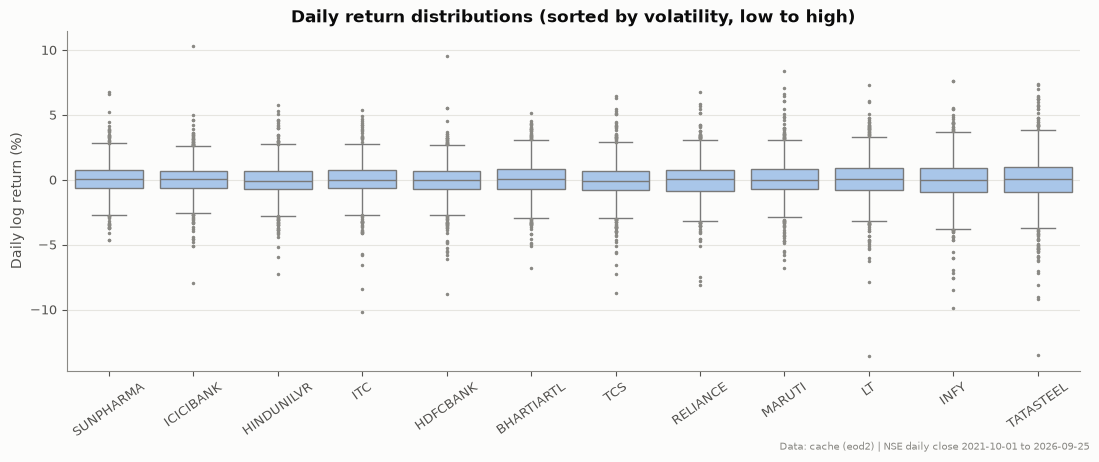

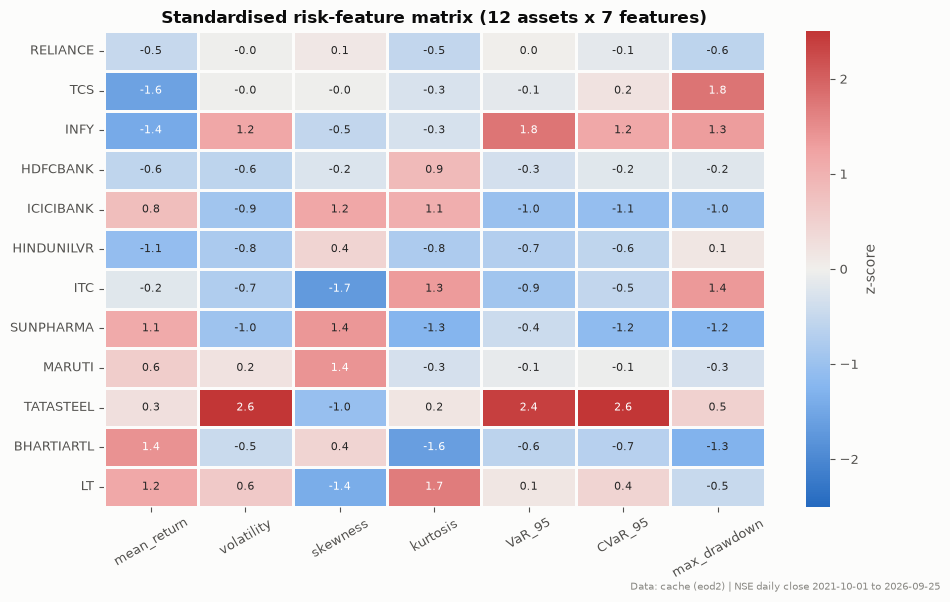

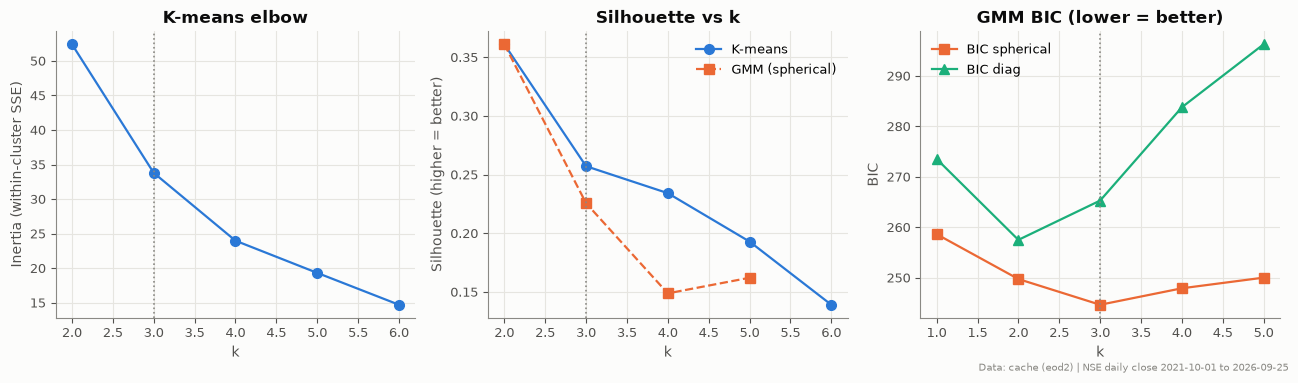

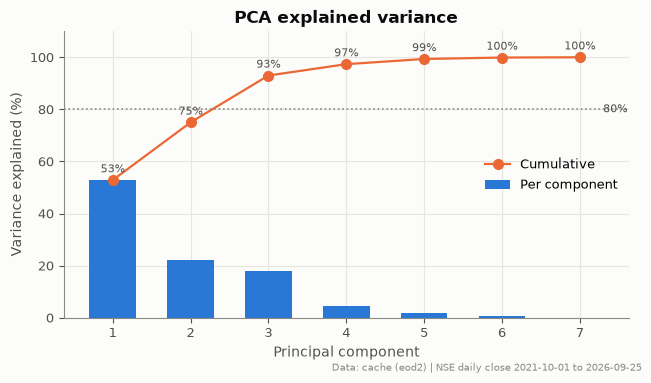

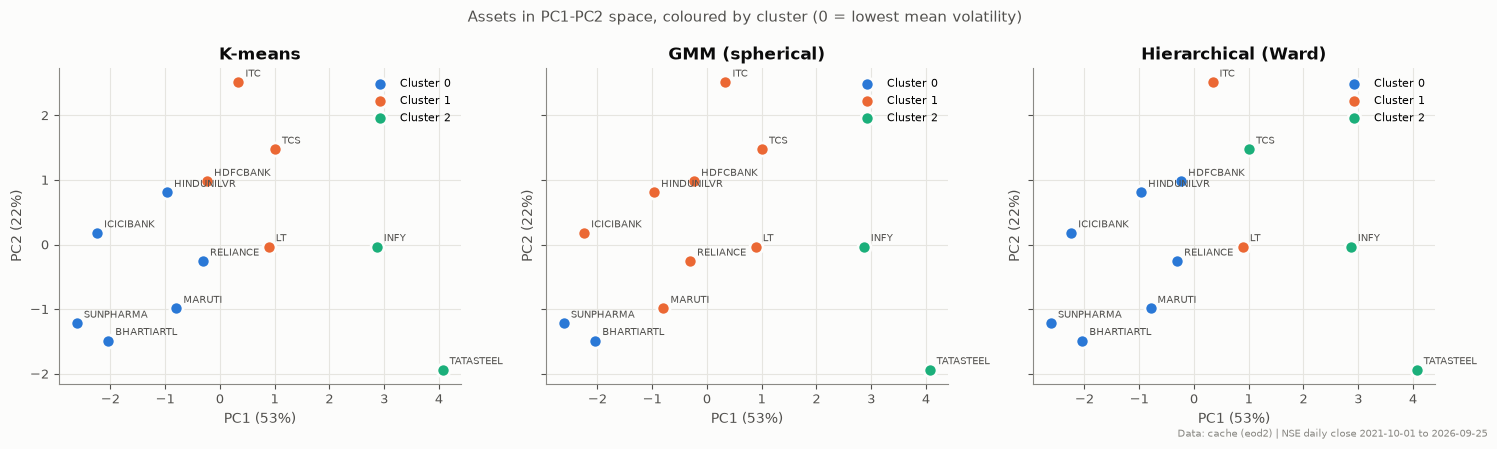

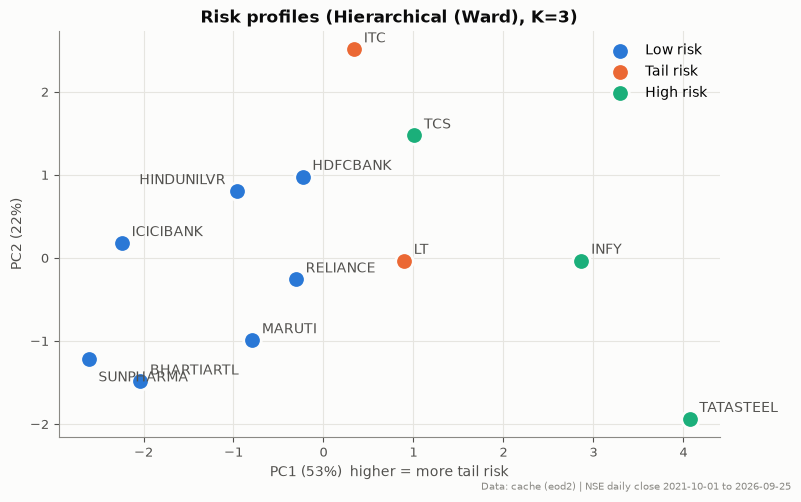

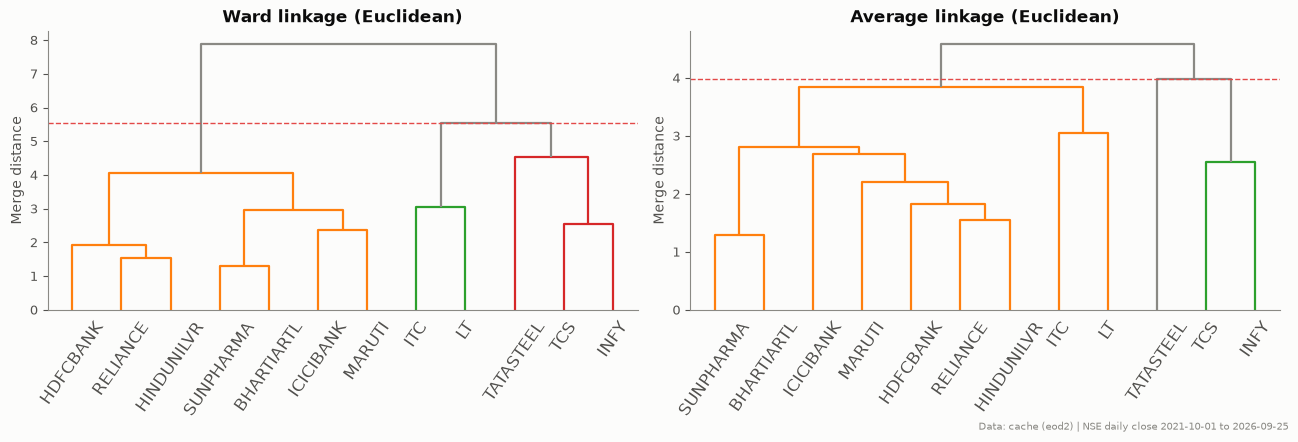

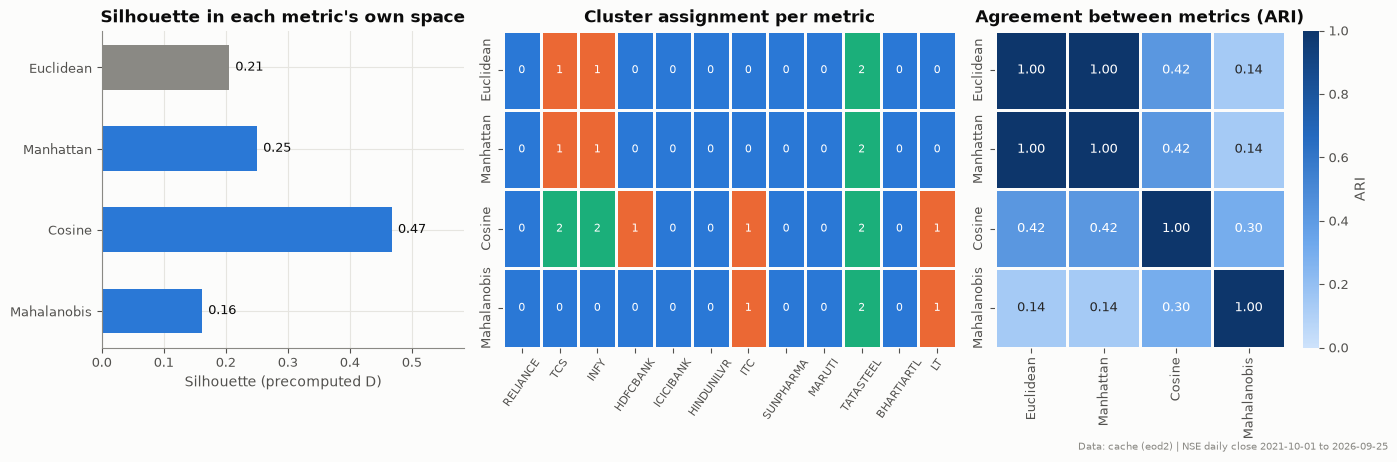

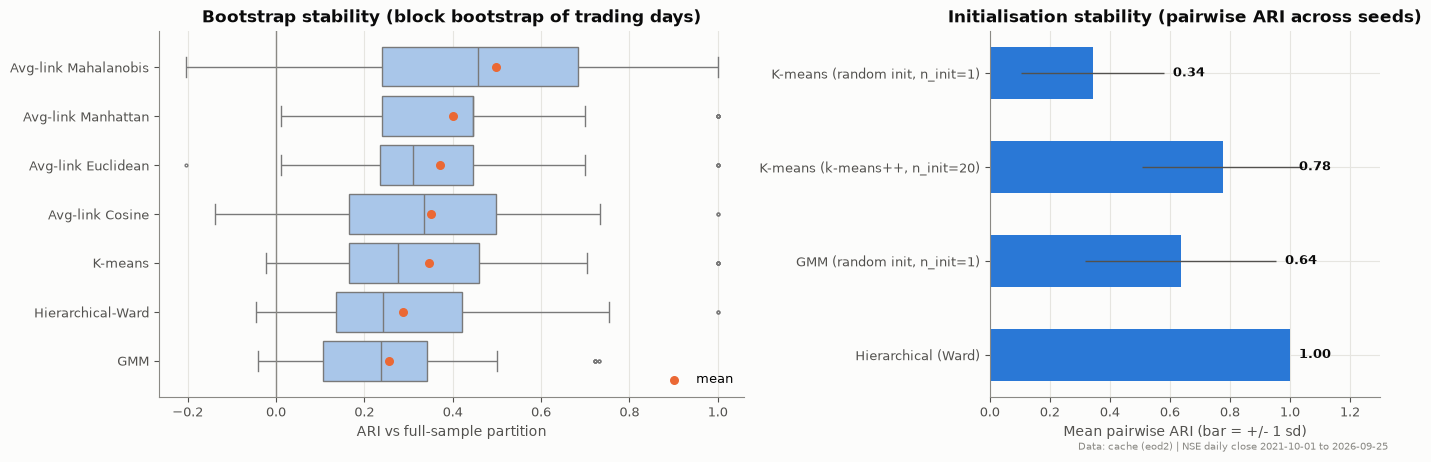

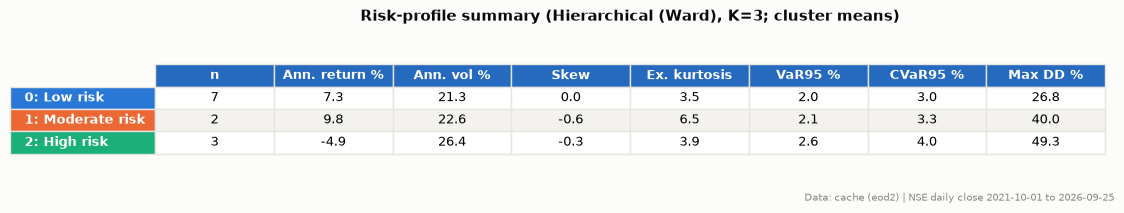

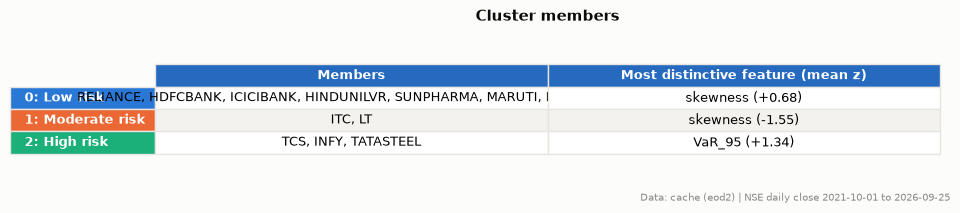

Saved figures to d:\ML Review 2\financial-risk-regime-project\outputs\figures


In [58]:
banner("PART A | Figures")
setup_style()
f = config.FIG_DIR
plot_return_distributions(returns, f / "A1_return_distributions.png", note)
plot_feature_heatmap(F, X, f / "A2_risk_feature_heatmap.png", note)
plot_model_selection(km_tab, gmm_tab, f / "A3_elbow_silhouette_bic.png", K, note)
plot_pca_variance(var_tab, f / "A4_pca_explained_variance.png", note)
plot_pca_clusters(Z2, names, labels, f / "A5_pca_clusters.png",
                      pca.explained_variance_ratio_, note)
plot_pca_single(Z2, names, labels[primary], {0: "Low risk", 1: "Tail risk", 2: "High risk"} if K == 3 else {},
                    f / "A5b_pca_primary.png", pca.explained_variance_ratio_,
                    f"Risk profiles ({primary}, K={K})", note)
plot_dendrograms(linkage_matrix(X, "ward"), linkage_matrix(X, "average"), names,
                     f / "A6_dendrograms.png", K, note)
mt = metric_tab[metric_tab["linkage"] == "average"].reset_index(drop=True)
plot_metric_comparison(mt, m_assign, metric_ari, f / "A7_distance_metric_comparison.png", note)
plot_stability(boot_raw, seed_tab, f / "A8_cluster_stability.png", note)
tbl = summary.drop(columns=["Members", "Most distinctive feature (mean z)"]).round(1).astype(str)
tbl.insert(0, "n", prof.groupby("cluster").size().values.astype(str))
plot_table(tbl, f / "A9_risk_profile_table.png",
               f"Risk-profile summary ({primary}, K={K}; cluster means)", note=note,
               row_colors=CAT[:K])
mem = pd.DataFrame({"Members": summary["Members"],
                    "Most distinctive feature (mean z)": summary["Most distinctive feature (mean z)"]})
plot_table(mem, f / "A9b_cluster_members.png", "Cluster members", col_width=3.2, note=note,
               row_colors=CAT[:K])
print(f"Saved figures to {f}")

results["part_a"] = {
    "data_source": src, "n_days": int(len(returns)), "assets": names,
    "window": [str(prices.index.min().date()), str(prices.index.max().date())],
    "k_best_silhouette_kmeans": k_sil, "gmm_best": {"covariance": gmm_cov, "k": k_bic},
    "K_used": K, "assignments": assign.to_dict(), "algorithm_scores": algo_scores.to_dict(),
    "algorithm_ari": algo_ari.to_dict(), "pca_components_kept": n_pc,
    "pca_explained": var_tab["explained_variance_ratio"].tolist(),
    "pca_before_after": pca_eval.to_dict(orient="records"),
    "metric_comparison": metric_tab.to_dict(orient="records"),
    "metric_ari": metric_ari.to_dict(), "mahalanobis_notes": mats["Mahalanobis"]["notes"],
    "cosine_near_zero_rows": mats["Cosine"]["notes"]["near_zero_rows"],
    "stability_seeds": seed_tab.to_dict(orient="records"),
    "stability_bootstrap": boot_sum.to_dict(orient="records"),
    "stability_loo": loo.to_dict(orient="records"),
    "primary_partition": primary, "seconds": round(time.time() - t0, 1),
}


---
# PART B: Market regimes with HMM and LDS (Unit IV)

## 9. Sum-Product (forward-backward) and Viterbi, written in NumPy
* **Forward** αₜ(j) = bⱼ(yₜ) Σᵢ αₜ₋₁(i) Aᵢⱼ  ·  **Backward** βₜ(i) = Σⱼ Aᵢⱼ bⱼ(yₜ₊₁) βₜ₊₁(j)
* **Sum-Product posterior** γₜ(i) = αₜ(i) βₜ(i) / p(y₁:T): sums over all paths, giving a marginal per day
* **Viterbi** δₜ(j) = bⱼ(yₜ) maxᵢ δₜ₋₁(i) Aᵢⱼ: maximises over paths, giving one best sequence

All recursions use log-sum-exp, so there is no underflow.

**Real-time vs retrospective:**
* **Filtered posterior** p(zₜ | y₁:ₜ) uses only data up to day t, so it is causal and suitable for real-time detection.
* **Smoothed posterior** p(zₜ | y₁:T) uses the full sequence, so it is retrospective (historical analysis).
* **Full-sequence Viterbi** gives the most probable complete path for the supplied sequence, so it is also retrospective.
* The out-of-sample comparison uses the one-step-ahead predictive density p(yₜ | y₁:ₜ₋₁) from causal filters only.

In [59]:
import itertools

import numpy as np
from scipy.special import logsumexp


def gaussian_log_emissions(y: np.ndarray, means: np.ndarray, variances: np.ndarray) -> np.ndarray:
    """log N(y_t; mu_j, s2_j) for univariate y. Returns (T, K)."""
    y = np.asarray(y, dtype=float).reshape(-1, 1)
    means = np.asarray(means, dtype=float).reshape(1, -1)
    variances = np.asarray(variances, dtype=float).reshape(1, -1)
    return -0.5 * (np.log(2 * np.pi * variances) + (y - means) ** 2 / variances)


def forward(log_pi, log_A, log_B):
    """log alpha (T, K) and total log-likelihood log p(y_{1:T})."""
    T, K = log_B.shape
    log_alpha = np.empty((T, K))
    log_alpha[0] = log_pi + log_B[0]
    for t in range(1, T):
        # log sum_i exp(log_alpha[t-1, i] + log_A[i, j])  for every j
        log_alpha[t] = logsumexp(log_alpha[t - 1][:, None] + log_A, axis=0) + log_B[t]
    return log_alpha, float(logsumexp(log_alpha[-1]))


def backward(log_A, log_B):
    T, K = log_B.shape
    log_beta = np.zeros((T, K))
    for t in range(T - 2, -1, -1):
        log_beta[t] = logsumexp(log_A + (log_B[t + 1] + log_beta[t + 1])[None, :], axis=1)
    return log_beta


def sum_product(pi, A, log_B):
    """Forward-backward. Returns dict with gamma (T,K), xi (T-1,K,K), loglik, log_alpha."""
    log_pi = np.log(np.asarray(pi, dtype=float) + 1e-300)
    log_A = np.log(np.asarray(A, dtype=float) + 1e-300)
    log_alpha, loglik = forward(log_pi, log_A, log_B)
    log_beta = backward(log_A, log_B)
    log_gamma = log_alpha + log_beta - loglik
    gamma = np.exp(log_gamma)
    gamma /= gamma.sum(axis=1, keepdims=True)          # remove round-off only
    log_xi = (log_alpha[:-1, :, None] + log_A[None, :, :]
              + (log_B[1:] + log_beta[1:])[:, None, :] - loglik)
    xi = np.exp(log_xi)
    return {"gamma": gamma, "xi": xi, "loglik": loglik, "log_alpha": log_alpha,
            "log_beta": log_beta}


def filtered_probs(log_alpha):
    """p(z_t | y_{1:t}) -- the causal (real-time) version of gamma."""
    return np.exp(log_alpha - logsumexp(log_alpha, axis=1, keepdims=True))


def one_step_predictive_loglik(pi, A, log_B):
    """log p(y_t | y_{1:t-1}) for every t (t=1 uses pi). Sums to the total log-likelihood.
    Used for an honest out-of-sample comparison with the Kalman filter."""
    log_pi = np.log(np.asarray(pi) + 1e-300)
    log_A = np.log(np.asarray(A) + 1e-300)
    log_alpha, _ = forward(log_pi, log_A, log_B)
    out = np.empty(len(log_B))
    out[0] = logsumexp(log_alpha[0])
    for t in range(1, len(log_B)):
        out[t] = logsumexp(log_alpha[t]) - logsumexp(log_alpha[t - 1])
    return out


def viterbi(pi, A, log_B):
    """Most probable state sequence argmax_z p(z_{1:T} | y_{1:T}) and its log joint prob."""
    log_pi = np.log(np.asarray(pi, dtype=float) + 1e-300)
    log_A = np.log(np.asarray(A, dtype=float) + 1e-300)
    T, K = log_B.shape
    delta = np.empty((T, K))
    psi = np.zeros((T, K), dtype=int)
    delta[0] = log_pi + log_B[0]
    for t in range(1, T):
        scores = delta[t - 1][:, None] + log_A          # (from i, to j)
        psi[t] = np.argmax(scores, axis=0)
        delta[t] = scores[psi[t], np.arange(K)] + log_B[t]
    path = np.empty(T, dtype=int)
    path[-1] = int(np.argmax(delta[-1]))
    for t in range(T - 2, -1, -1):
        path[t] = psi[t + 1, path[t + 1]]
    return path, float(delta[-1].max())


# ------------------------------------------------------------------ verification helpers
def brute_force(pi, A, B_obs):
    """Enumerate all K^T paths (tiny problems only).

    B_obs is the (T, K) matrix of emission *probabilities* b_j(y_t).
    Returns exact marginals p(z_t=i|y), p(y) and the best path.
    """
    T, K = B_obs.shape
    marg = np.zeros((T, K))
    total, best, best_p = 0.0, None, -1.0
    for path in itertools.product(range(K), repeat=T):
        p = pi[path[0]] * B_obs[0, path[0]]
        for t in range(1, T):
            p *= A[path[t - 1], path[t]] * B_obs[t, path[t]]
        total += p
        for t, s in enumerate(path):
            marg[t, s] += p
        if p > best_p:
            best, best_p = path, p
    return marg / total, total, np.array(best)


def toy_example():
    """Hand-checkable 2-state, 3-step HMM (weather-style) used in tests and the demo."""
    pi = np.array([0.6, 0.4])
    A = np.array([[0.7, 0.3],
                  [0.4, 0.6]])
    # emission probabilities for the observed sequence y = (up, down, down)
    # state 0 = "calm": p(up)=0.8 ; state 1 = "stressed": p(up)=0.3
    B_obs = np.array([[0.8, 0.3],
                      [0.2, 0.7],
                      [0.2, 0.7]])
    return pi, A, B_obs


## 10. Gaussian HMM (Baum-Welch via hmmlearn, restarts) and regime naming
States are named from **learned** parameters: largest σ → High-Volatility; of the other two, higher μ → Bull and lower μ → Bear.

In [60]:
import warnings

import numpy as np
import pandas as pd
from hmmlearn.hmm import GaussianHMM



def fit_hmm(y_train: np.ndarray, n_states=config.HMM_STATES, restarts=config.HMM_RESTARTS,
            n_iter=config.HMM_N_ITER, seed=config.SEED):
    """Fit a univariate Gaussian HMM with several random restarts; keep the best train log-lik."""
    Y = np.asarray(y_train, dtype=float).reshape(-1, 1)
    best, best_ll, lls = None, -np.inf, []
    for r in range(restarts):
        m = GaussianHMM(n_components=n_states, covariance_type="diag", n_iter=n_iter,
                        tol=1e-6, random_state=seed + r, min_covar=1e-4)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            m.fit(Y)
        ll = m.score(Y)
        lls.append(ll)
        if np.isfinite(ll) and ll > best_ll:
            best, best_ll = m, ll
    return best, {"restart_logliks": lls, "best_train_loglik": best_ll}


def params(model) -> dict:
    """Extract pi, A, means, variances as plain arrays (univariate)."""
    return {
        "pi": np.asarray(model.startprob_),
        "A": np.asarray(model.transmat_),
        "means": np.asarray(model.means_).ravel(),
        "variances": np.asarray(model.covars_).reshape(model.n_components, -1)[:, 0],
    }


def name_states(means, variances) -> dict:
    """Assign economic names from the *learned* parameters (state ids are arbitrary):
      * highest emission variance            -> "High-Volatility"
      * of the remaining, higher mean return -> "Bull"
      * the other                            -> "Bear"
    For K != 3 states are just ranked by variance.
    """
    K = len(means)
    order_var = np.argsort(variances)
    if K != 3:
        return {int(s): f"Regime-{i + 1} (vol rank)" for i, s in enumerate(order_var)}
    hv = int(order_var[-1])
    rest = [s for s in range(3) if s != hv]
    bull = max(rest, key=lambda s: means[s])
    bear = min(rest, key=lambda s: means[s])
    return {bull: "Bull", bear: "Bear", hv: "High-Volatility"}


def log_emissions(model, y) -> np.ndarray:
    p = params(model)
    return gaussian_log_emissions(y, p["means"], p["variances"])


def bic(model, y) -> float:
    K = model.n_components
    n_params = (K - 1) + K * (K - 1) + 2 * K          # pi, A, means, variances
    return -2 * model.score(np.asarray(y).reshape(-1, 1)) + n_params * np.log(len(y))


def model_selection(y_train, y_test, ks=(1, 2, 3, 4), seed=config.SEED) -> pd.DataFrame:
    """Train BIC and out-of-sample predictive log-likelihood for different numbers of states.
    K=1 is the i.i.d. Gaussian baseline."""
    rows = []
    y_all = np.concatenate([y_train, y_test])
    for K in ks:
        if K == 1:
            mu, var = y_train.mean(), y_train.var()
            ll_tr = gaussian_log_emissions(y_train, [mu], [var]).sum()
            ll_te = gaussian_log_emissions(y_test, [mu], [var]).sum()
            rows.append({"states": 1, "train_loglik": ll_tr, "bic": -2 * ll_tr + 2 * np.log(len(y_train)),
                         "test_loglik": ll_te, "test_loglik_per_day": ll_te / len(y_test)})
            continue
        m, _ = fit_hmm(y_train, K, restarts=6, seed=seed)
        p = params(m)
        lb = gaussian_log_emissions(y_all, p["means"], p["variances"])
        pred = one_step_predictive_loglik(p["pi"], p["A"], lb)
        ll_te = pred[len(y_train):].sum()
        rows.append({"states": K, "train_loglik": m.score(y_train.reshape(-1, 1)),
                     "bic": bic(m, y_train), "test_loglik": ll_te,
                     "test_loglik_per_day": ll_te / len(y_test)})
    return pd.DataFrame(rows)


## 11. Linear Dynamical System: NumPy Kalman filter, RTS smoother, MLE
xₜ = F xₜ₋₁ + c + wₜ,  yₜ = H xₜ + d + vₜ. **LDS-Trend** = random-walk drift of returns; **LDS-Vol** = AR(1) log-variance observed through log r².

In [61]:
from dataclasses import dataclass

import numpy as np
from scipy.optimize import minimize

LOG_CHI2_MEAN = -1.2704
LOG_CHI2_VAR = np.pi ** 2 / 2


@dataclass
class LDS:
    F: np.ndarray
    H: np.ndarray
    Q: np.ndarray
    R: np.ndarray
    c: np.ndarray
    d: np.ndarray
    x0: np.ndarray
    P0: np.ndarray

    # -------------------------------------------------------------- filter
    def filter(self, y):
        y = np.asarray(y, dtype=float).reshape(len(y), -1)
        if len(self.x0) == 1 and y.shape[1] == 1:
            return self._filter_scalar(y)
        T, n = len(y), len(self.x0)
        xp = np.zeros((T, n)); Pp = np.zeros((T, n, n))
        xf = np.zeros((T, n)); Pf = np.zeros((T, n, n))
        y_pred = np.zeros_like(y); S_all = np.zeros((T, y.shape[1], y.shape[1]))
        ll = np.zeros(T)
        x, P = self.x0.copy(), self.P0.copy()
        I = np.eye(n)
        for t in range(T):
            x_pred = self.F @ x + self.c
            P_pred = self.F @ P @ self.F.T + self.Q
            yhat = self.H @ x_pred + self.d
            S = self.H @ P_pred @ self.H.T + self.R
            Sinv = np.linalg.inv(S)
            K = P_pred @ self.H.T @ Sinv
            e = y[t] - yhat
            x = x_pred + K @ e
            P = (I - K @ self.H) @ P_pred
            P = (P + P.T) / 2
            sign, logdet = np.linalg.slogdet(2 * np.pi * S)
            ll[t] = -0.5 * (logdet + e @ Sinv @ e)
            xp[t], Pp[t], xf[t], Pf[t] = x_pred, P_pred, x, P
            y_pred[t], S_all[t] = yhat, S
        return {"x_pred": xp, "P_pred": Pp, "x_filt": xf, "P_filt": Pf,
                "y_pred": y_pred, "S": S_all, "loglik_t": ll, "loglik": float(ll.sum())}

    def _filter_scalar(self, y):
        """Same equations as filter(), with Python floats (about 20x faster for 1-D models)."""
        F, H, Q, R = float(self.F[0, 0]), float(self.H[0, 0]), float(self.Q[0, 0]), float(self.R[0, 0])
        c, d = float(self.c[0]), float(self.d[0])
        x, P = float(self.x0[0]), float(self.P0[0, 0])
        T = len(y)
        yv = y[:, 0]
        xp = np.empty(T); Pp = np.empty(T); xf = np.empty(T); Pf = np.empty(T)
        yp = np.empty(T); S_all = np.empty(T); ll = np.empty(T)
        log2pi = np.log(2 * np.pi)
        for t in range(T):
            x_pred = F * x + c
            P_pred = F * P * F + Q
            yhat = H * x_pred + d
            S = H * P_pred * H + R
            K = P_pred * H / S
            e = yv[t] - yhat
            x = x_pred + K * e
            P = (1.0 - K * H) * P_pred
            ll[t] = -0.5 * (log2pi + np.log(S) + e * e / S)
            xp[t], Pp[t], xf[t], Pf[t], yp[t], S_all[t] = x_pred, P_pred, x, P, yhat, S
        return {"x_pred": xp[:, None], "P_pred": Pp[:, None, None], "x_filt": xf[:, None],
                "P_filt": Pf[:, None, None], "y_pred": yp[:, None], "S": S_all[:, None, None],
                "loglik_t": ll, "loglik": float(ll.sum())}

    # -------------------------------------------------------------- RTS smoother
    def smooth(self, filt):
        xf, Pf, xp, Pp = filt["x_filt"], filt["P_filt"], filt["x_pred"], filt["P_pred"]
        T = len(xf)
        xs, Ps = xf.copy(), Pf.copy()
        for t in range(T - 2, -1, -1):
            J = Pf[t] @ self.F.T @ np.linalg.inv(Pp[t + 1])
            xs[t] = xf[t] + J @ (xs[t + 1] - xp[t + 1])
            Ps[t] = Pf[t] + J @ (Ps[t + 1] - Pp[t + 1]) @ J.T
        return xs, Ps


def _m(a):
    return np.atleast_2d(np.asarray(a, dtype=float))


# ------------------------------------------------------------------ LDS-Trend (local level)
def local_level(q, r, x0, p0):
    return LDS(F=_m(1.0), H=_m(1.0), Q=_m(q), R=_m(r), c=np.zeros(1), d=np.zeros(1),
               x0=np.array([x0], float), P0=_m(p0))


def fit_local_level(y_train):
    """MLE of (q, r) by L-BFGS on log-parameters; x0 = train mean, P0 = train variance."""
    y = np.asarray(y_train, float)
    x0, p0 = y.mean(), y.var()

    def nll(theta):
        q, r = np.exp(theta)
        return -local_level(q, r, x0, p0).filter(y)["loglik"]

    best = None
    for q0 in (1e-6, 1e-4, 1e-2):
        res = minimize(nll, x0=np.log([q0, y.var()]), method="L-BFGS-B",
                       bounds=[(np.log(1e-10), np.log(10.0)), (np.log(1e-4), np.log(100.0))])
        if best is None or res.fun < best.fun:
            best = res
    q, r = np.exp(best.x)
    return local_level(q, r, x0, p0), {"q": float(q), "r": float(r),
                                       "signal_to_noise_q_over_r": float(q / r),
                                       "train_loglik": float(-best.fun)}


# ------------------------------------------------------------------ LDS-Vol (log-variance AR(1))
def log_sq_obs(r, c=1e-3):
    return np.log(np.asarray(r, float) ** 2 + c)


def ar1_logvol(m, phi, sw2, h0=None, p0=None):
    h0 = m if h0 is None else h0
    p0 = sw2 / max(1 - phi ** 2, 1e-6) if p0 is None else p0
    return LDS(F=_m(phi), H=_m(1.0), Q=_m(sw2), R=_m(LOG_CHI2_VAR),
               c=np.array([(1 - phi) * m]), d=np.array([LOG_CHI2_MEAN]),
               x0=np.array([h0], float), P0=_m(p0))


def fit_logvol(r_train, c=1e-3):
    z = log_sq_obs(r_train, c)

    def nll(theta):
        m, a, ls = theta
        phi = np.tanh(a)
        return -ar1_logvol(m, phi, np.exp(ls)).filter(z)["loglik"]

    res = minimize(nll, x0=[z.mean() - LOG_CHI2_MEAN, np.arctanh(0.95), np.log(0.05)],
                   method="L-BFGS-B",
                   bounds=[(-10, 10), (np.arctanh(0.0), np.arctanh(0.999)), (np.log(1e-5), np.log(5))])
    m, a, ls = res.x
    phi, sw2 = float(np.tanh(a)), float(np.exp(ls))
    return ar1_logvol(m, phi, sw2), {"m": float(m), "phi": phi, "sigma_w2": sw2,
                                     "half_life_days": float(np.log(0.5) / np.log(phi)),
                                     "train_quasi_loglik": float(-res.fun)}


def logvol_predictive_loglik(model: LDS, r, mu, c=1e-3):
    """Plug-in one-step predictive density for the *returns*:
    r_t | past ~ N(mu, exp(h_{t|t-1} + P_{t|t-1}/2)) (log-normal mean of sigma^2).
    An approximation (the QML model is not an exact likelihood for r_t) -- reported as such."""
    f = model.filter(log_sq_obs(r, c))
    h, P = f["x_pred"][:, 0], f["P_pred"][:, 0, 0]
    s2 = np.exp(h + P / 2)
    r = np.asarray(r, float)
    return -0.5 * (np.log(2 * np.pi * s2) + (r - mu) ** 2 / s2), np.sqrt(s2)


In [62]:
t0 = time.time()


In [63]:
banner("PART B | Step 1  Load market index (NIFTY 50)")
px, src = load_index_prices(prefer=args.source, refresh=args.refresh_data)
note = f"Data: {src} | NIFTY 50 daily close {px.index.min():%Y-%m-%d} to {px.index.max():%Y-%m-%d}"
if "SYNTHETIC" in src:
    note = "SYNTHETIC DATA (simulated regime-switching index, NOT market data)"
r = log_returns(px) * config.RETURN_SCALE          # percent log returns
roll_vol = r.rolling(config.ROLLING_VOL_WINDOW).std() * np.sqrt(252)
train = r[r.index <= config.TRAIN_END]
test = r[r.index > config.TRAIN_END]
y_tr, y_te, y = train.values, test.values, r.values
dates = r.index
print(f"Source: {src}\nTrain: {train.index.min():%Y-%m-%d} -> {train.index.max():%Y-%m-%d} "
      f"({len(train)} days)  |  Test: {test.index.min():%Y-%m-%d} -> {test.index.max():%Y-%m-%d} "
      f"({len(test)} days)  [chronological, no shuffling]")



  PART B | Step 1  Load market index (NIFTY 50)
Source: cache (eod2)
Train: 2015-01-02 -> 2023-12-29 (2213 days)  |  Test: 2024-01-01 -> 2026-09-25 (680 days)  [chronological, no shuffling]


In [64]:
banner("PART B | Step 2  Fit 3-state Gaussian HMM (Baum-Welch, restarts)")
restarts = 4 if args.quick else config.HMM_RESTARTS
t_h = time.time()
model, info = fit_hmm(y_tr, config.HMM_STATES, restarts=restarts)
hmm_fit_s = time.time() - t_h
P = params(model)
names = name_states(P["means"], P["variances"])
print("Restart train log-likelihoods:", np.round(info["restart_logliks"], 2))
print("Initial probabilities pi:", np.round(P["pi"], 4))
order = sorted(names, key=lambda s: ["Bull", "Bear", "High-Volatility"].index(names[s]))
A_df = pd.DataFrame(P["A"], index=[f"{s}:{names[s]}" for s in range(3)],
                    columns=[f"{s}:{names[s]}" for s in range(3)])
print("Transition matrix A (rows = from):\n", A_df.round(4))
em = pd.DataFrame({"state": list(range(3)), "regime": [names[s] for s in range(3)],
                   "mean_%": P["means"], "std_%": np.sqrt(P["variances"]),
                   "expected_duration_days": 1 / (1 - np.diag(P["A"]))}).set_index("state")
print("Emission parameters (named from learned mean/variance):\n", em.round(4))
A_df.to_csv(config.TAB_DIR / "hmm_transition_matrix.csv")
em.to_csv(config.TAB_DIR / "hmm_emissions.csv")



  PART B | Step 2  Fit 3-state Gaussian HMM (Baum-Welch, restarts)
Restart train log-likelihoods: [-2844.99 -2844.32 -2844.99 -2844.99 -2844.32 -2844.32 -2844.32 -2844.99
 -2844.32 -2844.32]
Initial probabilities pi: [1. 0. 0.]
Transition matrix A (rows = from):
                    0:Bear  1:High-Volatility  2:Bull
0:Bear             0.9805             0.0079  0.0116
1:High-Volatility  0.1433             0.8567  0.0000
2:Bull             0.0116             0.0000  0.9884
Emission parameters (named from learned mean/variance):
                 regime  mean_%   std_%  expected_duration_days
state                                                         
0                 Bear -0.0028  1.0479                 51.3932
1      High-Volatility -0.3418  3.8765                  6.9766
2                 Bull  0.1168  0.6027                 85.9884


In [65]:
banner("PART B | Step 3  Sum-Product (forward-backward) inference -- our NumPy code")
lb = gaussian_log_emissions(y, P["means"], P["variances"])
t_sp = time.time()
out = sum_product(P["pi"], P["A"], lb)
sp_s = time.time() - t_sp
gamma = out["gamma"]
filt = filtered_probs(out["log_alpha"])
row_sums = gamma.sum(axis=1)
ref_gamma = model.predict_proba(y.reshape(-1, 1))
ref_ll = model.score(y.reshape(-1, 1))
print(f"log p(y_1:T): ours = {out['loglik']:.6f}   hmmlearn = {ref_ll:.6f}")
print(f"max |gamma_ours - gamma_hmmlearn| = {np.abs(gamma - ref_gamma).max():.2e}")
print(f"posterior rows sum to 1: min={row_sums.min():.12f}  max={row_sums.max():.12f}")
post = pd.DataFrame(gamma, index=dates, columns=[names[s] for s in range(3)])
post.to_csv(config.RES_DIR / "hmm_posterior_probabilities.csv")
print("\nSMOOTHED posterior p(z_t | y_1:T), last 8 trading days "
      "(retrospective: uses the full observation sequence):\n", post.tail(8).round(4))
filt_df = pd.DataFrame(filt, index=dates, columns=[names[s] for s in range(3)])
print("\nFILTERED posterior p(z_t | y_1:t), last 8 trading days "
      "(causal: uses only data up to day t -> real-time detection):\n", filt_df.tail(8).round(4))

# toy hand-checkable example
pi0, A0, B0 = toy_example()
toy = sum_product(pi0, A0, np.log(B0))
bf_marg, bf_p, bf_path = brute_force(pi0, A0, B0)
tv, _ = viterbi(pi0, A0, np.log(B0))
print(f"\nToy 2-state HMM check: p(y) forward={np.exp(toy['loglik']):.6f} brute-force={bf_p:.6f}; "
      f"max marginal diff={np.abs(toy['gamma'] - bf_marg).max():.1e}; "
      f"Viterbi {tv.tolist()} vs brute-force {bf_path.tolist()}")



  PART B | Step 3  Sum-Product (forward-backward) inference -- our NumPy code
log p(y_1:T): ours = -3642.937947   hmmlearn = -3642.937947
max |gamma_ours - gamma_hmmlearn| = 9.00e-13
posterior rows sum to 1: min=1.000000000000  max=1.000000000000

SMOOTHED posterior p(z_t | y_1:T), last 8 trading days (retrospective: uses the full observation sequence):
               Bear  High-Volatility    Bull
Date                                       
2026-09-16  0.0611           0.0000  0.9388
2026-09-17  0.0656           0.0000  0.9343
2026-09-18  0.0750           0.0000  0.9250
2026-09-21  0.0919           0.0000  0.9080
2026-09-22  0.1220           0.0001  0.8779
2026-09-23  0.1626           0.0002  0.8372
2026-09-24  0.2275           0.0005  0.7720
2026-09-25  0.2279           0.0008  0.7712

FILTERED posterior p(z_t | y_1:t), last 8 trading days (causal: uses only data up to day t -> real-time detection):
               Bear  High-Volatility    Bull
Date                                    

In [66]:
banner("PART B | Step 4  Viterbi decoding (max-product) -- distinct from Sum-Product")
vpath, vlogp = viterbi(P["pi"], P["A"], lb)
agree_lib = float((vpath == model.predict(y.reshape(-1, 1))).mean())
agree_post = float((vpath == gamma.argmax(1)).mean())
print("Full-sequence Viterbi decoding uses the whole observation sequence: the path is a "
      "retrospective (historical) labelling, not a real-time prediction.")
print(f"Viterbi path log p(z*, y) = {vlogp:.2f}; agreement with hmmlearn Viterbi = {agree_lib:.4f}")
print(f"Days where Viterbi state != argmax of Sum-Product marginal: "
      f"{int((vpath != gamma.argmax(1)).sum())} of {len(y)} ({1 - agree_post:.2%})")
regime_rows = []
for s in order:
    m = vpath == s
    runs = np.diff(np.flatnonzero(np.diff(np.r_[0, m.astype(int), 0])))[::2]
    regime_rows.append({"regime": names[s], "share_of_days_%": m.mean() * 100,
                        "share_test_%": m[len(y_tr):].mean() * 100,
                        "realised_mean_%": y[m].mean(), "realised_std_%": y[m].std(),
                        "n_episodes": len(runs), "avg_episode_days": runs.mean() if len(runs) else 0})
reg_tab = pd.DataFrame(regime_rows).set_index("regime")
print(reg_tab.round(3))
reg_tab.to_csv(config.TAB_DIR / "hmm_regime_statistics.csv")
pd.DataFrame({"viterbi_state": vpath, "viterbi_regime": [names[s] for s in vpath]},
             index=dates).to_csv(config.RES_DIR / "hmm_viterbi_path.csv")



  PART B | Step 4  Viterbi decoding (max-product) -- distinct from Sum-Product
Full-sequence Viterbi decoding uses the whole observation sequence: the path is a retrospective (historical) labelling, not a real-time prediction.
Viterbi path log p(z*, y) = -3704.75; agreement with hmmlearn Viterbi = 1.0000
Days where Viterbi state != argmax of Sum-Product marginal: 107 of 2893 (3.70%)
                 share_of_days_%  share_test_%  realised_mean_%  realised_std_%  n_episodes  avg_episode_days
regime                                                                                                       
Bull                      50.052        64.853            0.089           0.599          11           131.636
Bear                      48.185        34.706           -0.008           1.059          17            82.000
High-Volatility            1.763         0.441           -0.301           4.298           6             8.500


In [67]:
banner("PART B | Step 5  HMM model selection & out-of-sample likelihood")
sel = model_selection(y_tr, y_te, ks=(1, 2, 3, 4))
print(sel.round(4).to_string(index=False))
k_bic_hmm = int(sel.loc[sel["bic"].idxmin(), "states"])
k_test_hmm = int(sel.loc[sel["test_loglik_per_day"].idxmax(), "states"])
if k_bic_hmm != k_test_hmm:
    tl = sel.set_index("states")["test_loglik_per_day"]
    print(f"BIC selects the {k_bic_hmm}-state HMM as a balance between model fit and complexity. "
          f"The {k_test_hmm}-state model achieves a slightly better held-out predictive log-likelihood "
          f"({tl[k_test_hmm]:.4f} vs {tl[k_bic_hmm]:.4f} per day). We retain {config.HMM_STATES} states "
          "because they support the intended Bull, Bear and High-Volatility interpretation, while "
          "acknowledging that the optimal number of states depends on the selection criterion.")
sel.to_csv(config.TAB_DIR / "hmm_model_selection.csv", index=False)



  PART B | Step 5  HMM model selection & out-of-sample likelihood
 states  train_loglik       bic  test_loglik  test_loglik_per_day
      1    -3295.4335 6606.2713    -886.3375              -1.3034
      2    -2923.3784 5900.6716    -800.9923              -1.1779
      3    -2844.3215 5796.4725    -798.6164              -1.1744
      4    -2830.1146 5837.3775    -797.3938              -1.1726
BIC selects the 3-state HMM as a balance between model fit and complexity. The 4-state model achieves a slightly better held-out predictive log-likelihood (-1.1726 vs -1.1744 per day). We retain 3 states because they support the intended Bull, Bear and High-Volatility interpretation, while acknowledging that the optimal number of states depends on the selection criterion.


In [68]:
banner("PART B | Step 6  Linear Dynamical Systems (NumPy Kalman filter + RTS smoother)")
t_l = time.time()
ll_model, ll_info = fit_local_level(y_tr)
f_tr = ll_model.filter(y)
trend_s, _ = ll_model.smooth(f_tr)
lv_model, lv_info = fit_logvol(y_tr)
f_lv = lv_model.filter(log_sq_obs(y))
h_s, Ph_s = lv_model.smooth(f_lv)
lds_s = time.time() - t_l
lds_sigma = np.exp(h_s[:, 0] / 2 + Ph_s[:, 0, 0] / 8)
lv_pred_ll, _ = logvol_predictive_loglik(lv_model, y, y_tr.mean())
print("LDS-Trend (local level) MLE:", {k: round(v, 8) for k, v in ll_info.items()})
print("LDS-Vol (AR(1) log-variance) MLE:", {k: round(v, 5) for k, v in lv_info.items()})
hmm_mean = gamma @ P["means"]
hmm_sigma = np.sqrt(gamma @ (P["variances"] + P["means"] ** 2) - hmm_mean ** 2)
rv_daily = (roll_vol / np.sqrt(252)).values
ok = ~np.isnan(rv_daily)
corr_hmm = float(np.corrcoef(hmm_sigma[ok], rv_daily[ok])[0, 1])
corr_lds = float(np.corrcoef(lds_sigma[ok], rv_daily[ok])[0, 1])
print(f"Correlation with 21-day realised vol: HMM sigma_t = {corr_hmm:.3f} | LDS-Vol sigma_t = {corr_lds:.3f}")
pd.DataFrame({"return_%": y, "lds_trend_smoothed": trend_s[:, 0], "lds_sigma_smoothed": lds_sigma,
              "hmm_expected_mean": hmm_mean, "hmm_sigma": hmm_sigma},
             index=dates).to_csv(config.RES_DIR / "lds_and_hmm_latent_estimates.csv")



  PART B | Step 6  Linear Dynamical Systems (NumPy Kalman filter + RTS smoother)
LDS-Trend (local level) MLE: {'q': 0.0, 'r': 1.15122273, 'signal_to_noise_q_over_r': 0.0, 'train_loglik': -3299.2847243}
LDS-Vol (AR(1) log-variance) MLE: {'m': -0.31027, 'phi': 0.98766, 'sigma_w2': 0.00946, 'half_life_days': 55.82976, 'train_quasi_loglik': -4756.6313}
Correlation with 21-day realised vol: HMM sigma_t = 0.789 | LDS-Vol sigma_t = 0.799


In [69]:
banner("PART B | Step 7  HMM vs LDS: one-step-ahead predictive log-likelihood on TEST")
n_tr = len(y_tr)
hmm_pred = one_step_predictive_loglik(P["pi"], P["A"], lb)
iid = gaussian_log_emissions(y_te, [y_tr.mean()], [y_tr.var()]).ravel()
comp = pd.DataFrame([
    {"model": "i.i.d. Gaussian (baseline)", "test_loglik_per_day": iid.mean(),
     "latent_state": "none", "exact_likelihood": True},
    {"model": "LDS-Trend (Kalman, continuous drift)", "test_loglik_per_day": f_tr["loglik_t"][n_tr:].mean(),
     "latent_state": "continuous", "exact_likelihood": True},
    {"model": "LDS-Vol (Kalman QML, plug-in density)*", "test_loglik_per_day": lv_pred_ll[n_tr:].mean(),
     "latent_state": "continuous", "exact_likelihood": False},
    {"model": "HMM-3 (forward filter, discrete)", "test_loglik_per_day": hmm_pred[n_tr:].mean(),
     "latent_state": "discrete", "exact_likelihood": True},
])
print(comp.round(4).to_string(index=False))
print("Protocol: parameters fitted on train only; each test day scored with p(y_t | y_1:t-1) "
      "from a causal filter, same data and units (percent log return) for every model.\n"
      "* LDS-Vol is a quasi-likelihood linearisation; its return density is an approximation.")
comp.to_csv(config.TAB_DIR / "hmm_vs_lds_predictive.csv", index=False)
qual = pd.DataFrame({
    "Aspect": ["Latent state", "Interpretability", "Abrupt transitions", "Smooth trends",
               "Volatility clustering", "Test log-lik / day", "Corr. with realised vol",
               "Fit time (s)", "Key assumptions"],
    "HMM (3 Gaussian states)": [
        "Discrete z_t in {Bull, Bear, High-Vol}", "Named regimes + transition probabilities",
        "Yes: jump between states in one step", "Only as a mixture of a few levels",
        "Yes: high-variance state", f"{hmm_pred[n_tr:].mean():.4f}", f"{corr_hmm:.3f}",
        f"{hmm_fit_s:.1f} (EM x{restarts})", "Markov switching, Gaussian emissions, constant params"],
    "LDS (Kalman)": [
        "Continuous x_t in R (drift or log-variance)", "No labels; a smooth continuous signal",
        "No: Gaussian random-walk moves gradually", "Yes: optimal linear-Gaussian smoothing",
        "Only LDS-Vol (via log r^2 transform)",
        f"Trend {f_tr['loglik_t'][n_tr:].mean():.4f} / Vol* {lv_pred_ll[n_tr:].mean():.4f}",
        f"{corr_lds:.3f} (LDS-Vol)", f"{lds_s:.1f} (both models)",
        "Linear dynamics, Gaussian noise, constant Q and R"],
})
qual.to_csv(config.TAB_DIR / "hmm_vs_lds_comparison.csv", index=False)
print(qual.to_string(index=False))



  PART B | Step 7  HMM vs LDS: one-step-ahead predictive log-likelihood on TEST
                                 model  test_loglik_per_day latent_state  exact_likelihood
            i.i.d. Gaussian (baseline)              -1.3034         none              True
  LDS-Trend (Kalman, continuous drift)              -1.3036   continuous              True
LDS-Vol (Kalman QML, plug-in density)*              -1.2423   continuous             False
      HMM-3 (forward filter, discrete)              -1.1744     discrete              True
Protocol: parameters fitted on train only; each test day scored with p(y_t | y_1:t-1) from a causal filter, same data and units (percent log return) for every model.
* LDS-Vol is a quasi-likelihood linearisation; its return density is an approximation.
                 Aspect                               HMM (3 Gaussian states)                                      LDS (Kalman)
           Latent state                Discrete z_t in {Bull, Bear, High-Vol}      


  PART B | Figures


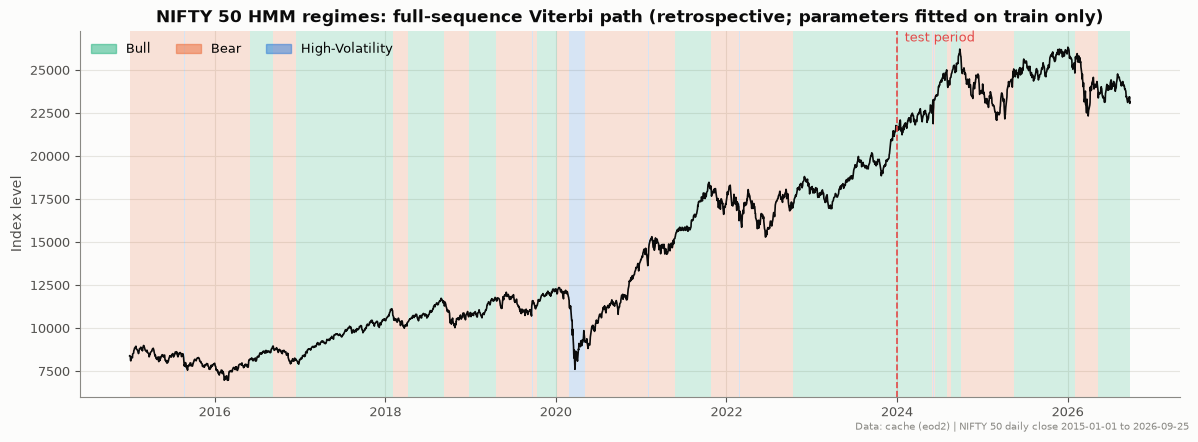

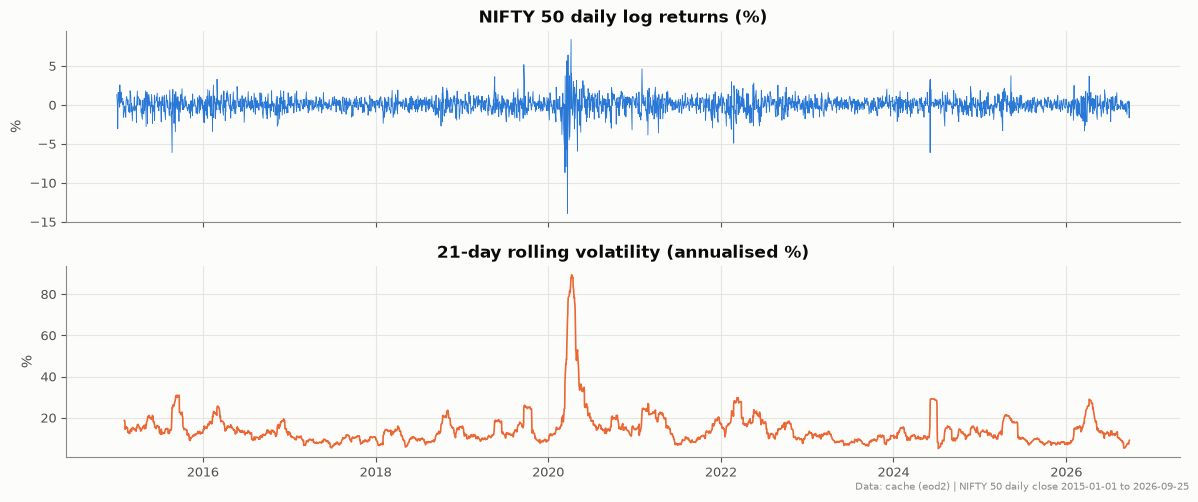

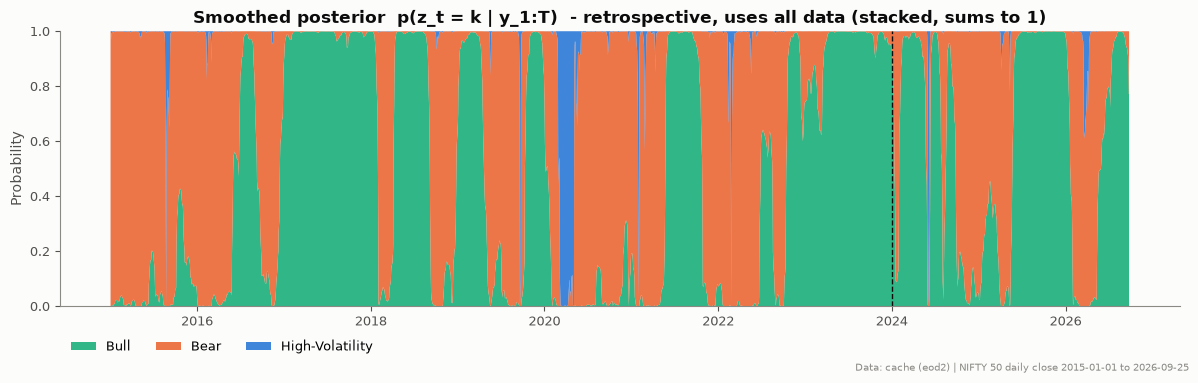

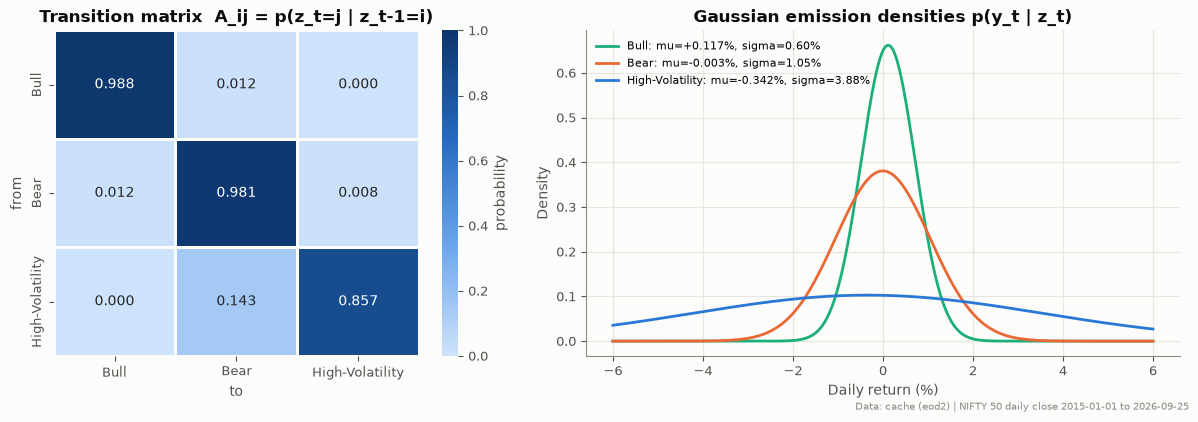

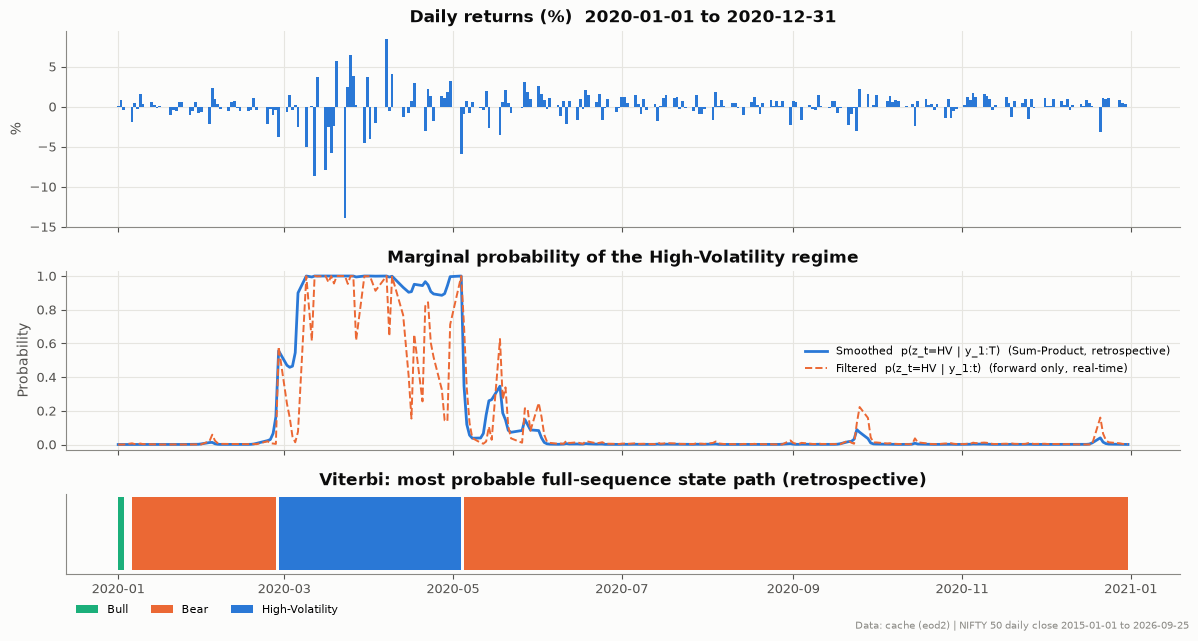

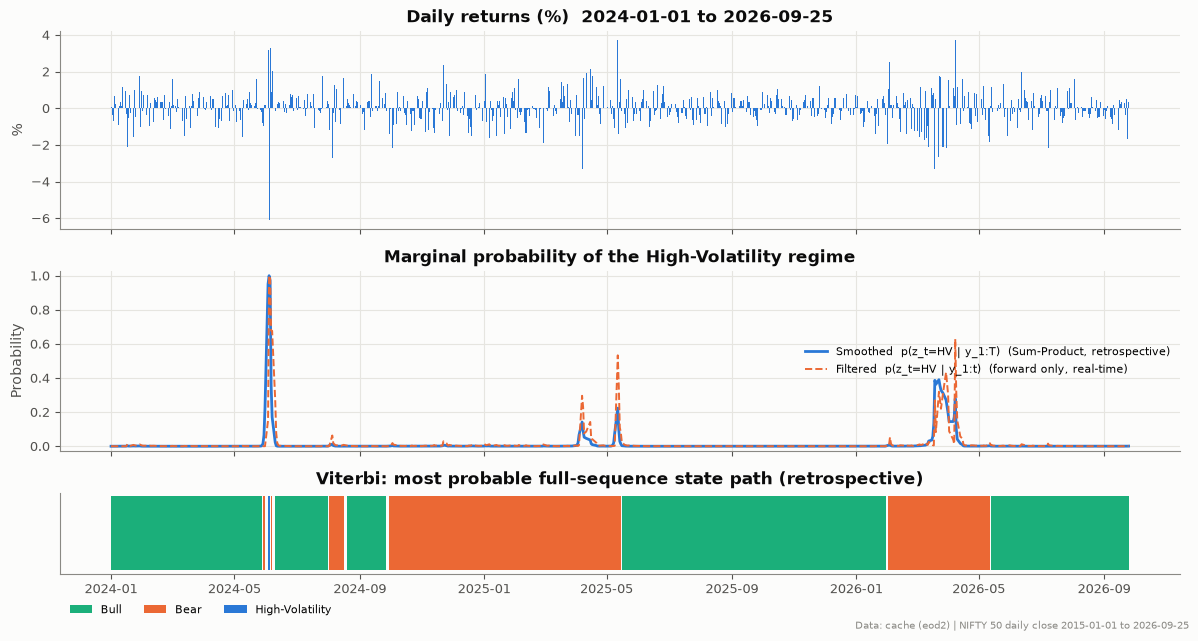

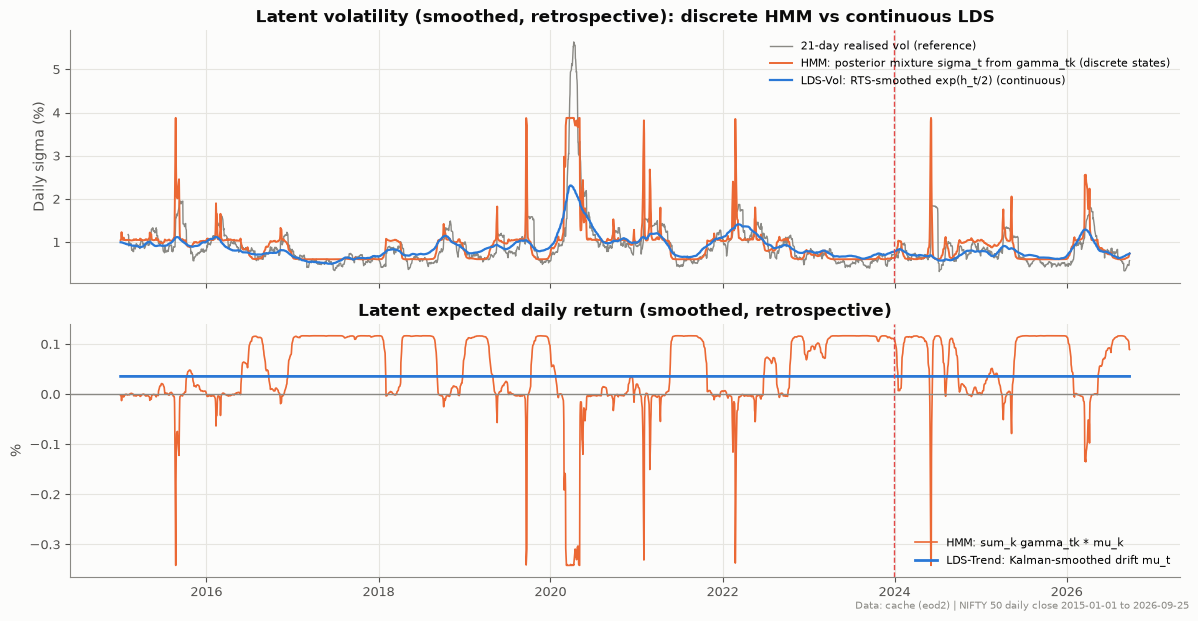

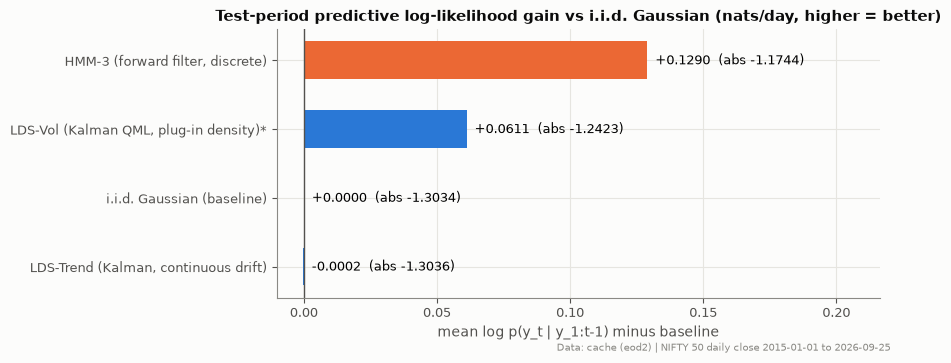

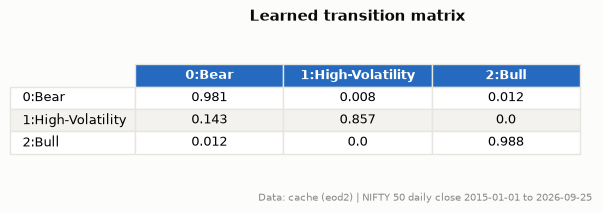

Saved figures to d:\ML Review 2\financial-risk-regime-project\outputs\figures


In [70]:
banner("PART B | Figures")
setup_style()
f = config.FIG_DIR
plot_index_regimes(px.loc[dates], dates, vpath, names, config.TRAIN_END,
                       f / "B1_nifty_regimes_viterbi.png",
                       "NIFTY 50 HMM regimes: full-sequence Viterbi path (retrospective; parameters fitted on train only)", note)
plot_returns_vol(r, roll_vol, f / "B2_returns_rolling_vol.png", note)
plot_posteriors(dates, gamma, names, f / "B3_posterior_probabilities.png", config.TRAIN_END, note)
plot_hmm_params(P["A"], P["means"], P["variances"], names, f / "B4_transition_emissions.png", note)
plot_sp_vs_viterbi(dates, y, gamma, filt, vpath, names, ("2020-01-01", "2020-12-31"),
                       f / "B5_sumproduct_vs_viterbi_2020.png", note)
plot_sp_vs_viterbi(dates, y, gamma, filt, vpath, names, ("2024-01-01", str(dates.max().date())),
                       f / "B5b_sumproduct_vs_viterbi_test.png", note)
plot_lds_comparison(dates, rv_daily, hmm_sigma, lds_sigma, trend_s[:, 0], hmm_mean,
                        config.TRAIN_END, f / "B6_hmm_vs_lds.png", note)
plot_predictive(comp, f / "B7_predictive_loglik.png", note)
plot_table(A_df.round(3), f / "B8_transition_table.png", "Learned transition matrix", note=note)
print(f"Saved figures to {f}")

results["part_b"] = {
    "data_source": src, "train_days": int(len(y_tr)), "test_days": int(len(y_te)),
    "train_window": [str(train.index.min().date()), str(train.index.max().date())],
    "test_window": [str(test.index.min().date()), str(test.index.max().date())],
    "pi": P["pi"], "A": P["A"], "means": P["means"], "variances": P["variances"],
    "state_names": names, "loglik_ours": out["loglik"], "loglik_hmmlearn": ref_ll,
    "max_gamma_diff_vs_hmmlearn": float(np.abs(gamma - ref_gamma).max()),
    "posterior_row_sum_range": [float(row_sums.min()), float(row_sums.max())],
    "viterbi_agreement_hmmlearn": agree_lib, "viterbi_vs_posterior_argmax_agreement": agree_post,
    "toy_check": {"p_forward": float(np.exp(toy["loglik"])), "p_bruteforce": float(bf_p),
                  "max_marginal_diff": float(np.abs(toy["gamma"] - bf_marg).max()),
                  "viterbi": tv.tolist(), "bruteforce_best": bf_path.tolist()},
    "model_selection": sel.to_dict(orient="records"),
    "lds_trend": ll_info, "lds_vol": lv_info,
    "corr_realised_vol": {"hmm": corr_hmm, "lds_vol": corr_lds},
    "predictive_comparison": comp.to_dict(orient="records"),
    "regime_stats": reg_tab.reset_index().to_dict(orient="records"),
    "timing_s": {"hmm_fit": hmm_fit_s, "sum_product": sp_s, "lds_fit_and_smooth": lds_s},
    "seconds": round(time.time() - t0, 1),
}


## 12. Save the summary

In [71]:
results["total_seconds"] = round(time.time() - T_START, 1)
name = "results_synthetic.json" if args.source == "synthetic" else "results.json"
(config.RES_DIR / name).write_text(json.dumps(jsonable(results), indent=2))
banner(f"DONE in {results['total_seconds']} s  |  results -> {config.RES_DIR / name}")


  DONE in 114.0 s  |  results -> d:\ML Review 2\financial-risk-regime-project\outputs\results\results.json


## 13. Verification checks (the key tests, run inline)

In [72]:
def check(name, cond):
    print(("PASS " if cond else "FAIL ") + name)
    assert cond, name

# 1) Sum-Product on the toy HMM equals brute-force enumeration of all 2^3 paths; hand-computed alphas
pi0, A0, B0 = toy_example()
toy = sum_product(pi0, A0, np.log(B0))
bf_marg, bf_p, bf_best = brute_force(pi0, A0, B0)
la, ll = forward(np.log(pi0), np.log(A0), np.log(B0))
check("toy p(y) = brute force (0.10248)", abs(np.exp(toy["loglik"]) - bf_p) < 1e-12)
check("toy marginals = brute force", np.allclose(toy["gamma"], bf_marg, atol=1e-12))
check("hand-computed alpha values", np.allclose(np.exp(la), [[0.48, 0.12], [0.0768, 0.1512], [0.022848, 0.079632]]))
check("toy Viterbi = brute-force best path", viterbi(pi0, A0, np.log(B0))[0].tolist() == bf_best.tolist())

# 2) On the real NIFTY model: our code = hmmlearn, posteriors normalised, xi consistent
check("log-likelihood = hmmlearn", abs(out["loglik"] - ref_ll) < 1e-6)
check("posteriors = hmmlearn (< 1e-8)", np.abs(gamma - ref_gamma).max() < 1e-8)
check("posterior rows sum to 1", np.allclose(gamma.sum(1), 1))
check("sum_j xi_t(i,j) = gamma_t(i)", np.allclose(out["xi"].sum(2), gamma[:-1], atol=1e-8))
check("Viterbi = hmmlearn on every day", agree_lib == 1.0)
check("regime names from learned params", set(names.values()) == {"Bull", "Bear", "High-Volatility"})

# 3) Distances are valid matrices; Ward refused on precomputed D
for m, obj in mats.items():
    check(f"{m} matrix valid", all(validate_distance_matrix(obj["D"]).values()))
try:
    hierarchical_precomputed(mats["Manhattan"]["D"], 3, "ward"); check("Ward refused", False)
except ValueError:
    check("Ward refused on precomputed distances", True)

# 4) Kalman filter + smoother recover a simulated random walk better than raw observations
rng = np.random.default_rng(0)
xt = np.cumsum(rng.normal(0, np.sqrt(0.05), 500)); yt = xt + rng.normal(0, 1, 500)
kf = local_level(0.05, 1.0, 0.0, 1.0); fk = kf.filter(yt); xs_, _ = kf.smooth(fk)
rm = lambda e: np.sqrt(np.mean(e ** 2))
check("Kalman: smoothed < filtered < raw error", rm(xs_[:, 0] - xt) < rm(fk["x_filt"][:, 0] - xt) < rm(yt - xt))
print("\nAll checks passed.")

PASS toy p(y) = brute force (0.10248)
PASS toy marginals = brute force
PASS hand-computed alpha values
PASS toy Viterbi = brute-force best path
PASS log-likelihood = hmmlearn
PASS posteriors = hmmlearn (< 1e-8)
PASS posterior rows sum to 1
PASS sum_j xi_t(i,j) = gamma_t(i)
PASS Viterbi = hmmlearn on every day
PASS regime names from learned params
PASS Euclidean matrix valid
PASS Manhattan matrix valid
PASS Cosine matrix valid
PASS Mahalanobis matrix valid
PASS Ward refused on precomputed distances
PASS Kalman: smoothed < filtered < raw error

All checks passed.


## Conclusion
* **Part A:** three risk tiers: a low-risk core, a tail-risk pair (ITC, LT) and a high-risk group (TCS, INFY, TATASTEEL). The choice of distance changes the clusters; Mahalanobis is the most stable.
* **Part B:** BIC selects the 3-state HMM as a balance between fit and complexity; the 4-state model has a slightly better held-out log-likelihood (−1.1726 vs −1.1744 per day). We keep 3 states for the Bull, Bear and High-Volatility interpretation, so the optimal number of states depends on the criterion. The regime timeline (full-sequence Viterbi and smoothed posteriors) is a retrospective labelling that includes the COVID-2020 crash; real-time detection would use the filtered posterior. Our Sum-Product and Viterbi match hmmlearn exactly. On unseen 2024–26 data the HMM predicts better than the Kalman LDS and the i.i.d. baseline.
* **Limitations:** only 12 assets; regime names are statistical interpretations; the LDS-Vol density is approximate; prices are not dividend-adjusted.
* **Future scope:** a larger universe, multivariate HMM emissions, a regime-aware portfolio.